# NAIM ile eksik klinik verilerde CKD sınıflandırması

Cinar Lab görevi. Veri: UCI Chronic Kidney Disease (400 hasta, 24 özellik). Model: NAIM ([Caruso, Soda, Guarrasi 2026](https://doi.org/10.1016/j.aiopen.2026.02.005), [kod](https://github.com/cosbidev/NAIM), commit `2f15af8`); karşılaştırma: SVM, KNN, Random Forest.

| Bölüm | İçerik |
|---|---|
| 0 | Ortam, Drive, NAIM reposu, veri dosyası (MD5 doğrulamalı) |
| 1 | Veri analizi ve sabit %70/%15/%15 tabakalı bölme |
| 2 | Orijinal veride eğitim: NAIM (repo protokolü), SVM, KNN, RF |
| 3 | Ek %10/%30/%50 eksiklik maskeleri ve aynı modellerin yeniden eğitimi |
| Tanı | NAIM'in repo protokolüyle düşük çıkmasının nedeni (TANI 1–4) |
| Uyarlanmış NAIM | Isınma ve sabır süreleri adım sayısına göre ×6; 4 koşul × 3 seed |
| Final | 5 model × 4 koşul tablo, grafik, hata analizi ve yorum |

Bütün çıktılar Drive'da `cinar-lab/outputs/` altına kaydedilir. Eğitim döngüleri yarıda kalırsa kaldığı yerden devam eder. Colab T4 GPU'da baştan sona çalıştırma yaklaşık 1,5 saat sürer (en uzunu uyarlanmış NAIM, ≈ 1 saat).

## 0 · Ortam

In [1]:
import sys, torch, sklearn, pandas as pd, numpy as np
print(sys.version.split()[0])
print("torch", torch.__version__, "| cuda:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "GPU yok")
print("sklearn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

3.13.15
torch 2.11.0+cu130 | cuda: True | Tesla T4
sklearn 1.6.1 | pandas 2.2.3 | numpy 2.1.3


In [2]:
import os, hashlib, subprocess

# Drive bağlanabilirse çıktılar kalıcı olarak Drive'a yazılır; bağlanamazsa Colab'ın geçici diskine.
try:
    from google.colab import drive
    drive.mount("/content/drive", timeout_ms=60000)
    PROJE = "/content/drive/MyDrive/cinar-lab"
except Exception as e:
    print("Drive bağlanamadı, geçici disk kullanılıyor:", e)
    PROJE = "/content/cinar-lab"
VERI = f"{PROJE}/data/chronic_kidney_disease_full.arff"
CIKTI = f"{PROJE}/outputs"
os.makedirs(os.path.dirname(VERI), exist_ok=True)
os.makedirs(CIKTI, exist_ok=True)

# NAIM reposu, yerel kopyadaki commit'e sabitlenmiş
NAIM_DIR = "/content/NAIM"
if not os.path.exists(NAIM_DIR):
    subprocess.run(["git", "clone", "-q", "https://github.com/cosbidev/NAIM", NAIM_DIR], check=True)
subprocess.run(["git", "-C", NAIM_DIR, "checkout", "-q", "2f15af8"], check=True)
print("NAIM commit:", subprocess.run(["git", "-C", NAIM_DIR, "rev-parse", "--short", "HEAD"], capture_output=True, text=True).stdout.strip())
print("proje klasörü:", PROJE)

Mounted at /content/drive
NAIM commit: 2f15af8
proje klasörü: /content/drive/MyDrive/cinar-lab


In [3]:
# Veri: UCI Chronic Kidney Disease, chronic_kidney_disease_full.arff (depodaki data/ klasöründe).
# Dosya Drive'daki cinar-lab/data/ klasöründe yoksa Colab yükleme penceresi açılır; MD5 ile kontrol edilir.
BEKLENEN_MD5 = "0c9f5965ed459e2f70002c278c39b03b"
md5 = lambda yol: hashlib.md5(open(yol, "rb").read()).hexdigest()
if not os.path.exists(VERI):
    try:
        from google.colab import files
        print("chronic_kidney_disease_full.arff dosyasını yükleyin:")
        yuklenen = files.upload()
        open(VERI, "wb").write(yuklenen["chronic_kidney_disease_full.arff"])
    except ImportError:
        raise FileNotFoundError(f"{VERI} bulunamadı; data/ klasöründeki dosyayı bu yola kopyalayın")
assert md5(VERI) == BEKLENEN_MD5, "veri dosyasının MD5 değeri beklenenle uyuşmuyor"
print("veri:", VERI, "|", os.path.getsize(VERI), "bayt | MD5 doğrulandı")

veri: /content/drive/MyDrive/cinar-lab/data/chronic_kidney_disease_full.arff | 47277 bayt | MD5 doğrulandı


In [4]:
import json, random, copy, time, importlib.util, sys
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt

def tohum(seed):
    """Python, NumPy ve PyTorch rastgeleliğini sabitler (repo: CMC_utils.miscellaneous.seed_all ile aynı)."""
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False

CIHAZ = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEEDLER = [42, 123, 2026]
RENK = {"ckd": "#2a78d6", "notckd": "#eb6834"}
print("cihaz:", CIHAZ)

cihaz: cuda


## 1 · Veri analizi

ARFF dosyasında 3 bozuk satır var: 2 satırın sonunda fazladan virgül, 1 satırda `no,,no` (çift virgül). Bunlar okunurken düzeltiliyor; `?` eksik değer (NaN) olarak alınıyor. Değişken türleri ARFF tanımını izliyor: 11 sayısal, 13 kategorik (`sg`, `al`, `su` sıralı olsa da ARFF'te nominal tanımlı, kategorik bırakıldı).

In [5]:
KOLONLAR = ("age bp sg al su rbc pc pcc ba bgr bu sc sod pot hemo pcv "
            "wbcc rbcc htn dm cad appet pe ane class").split()
SAYISAL = "age bp bgr bu sc sod pot hemo pcv wbcc rbcc".split()
KATEGORIK = [k for k in KOLONLAR[:-1] if k not in SAYISAL]
OZELLIK = KOLONLAR[:-1]
# ARFF @attribute satırlarındaki kategori seviyeleri (sıra = NAIM tamsayı kodu)
SEVIYE = {"sg": ["1.005", "1.010", "1.015", "1.020", "1.025"], "al": list("012345"), "su": list("012345"),
          "rbc": ["normal", "abnormal"], "pc": ["normal", "abnormal"], "pcc": ["notpresent", "present"],
          "ba": ["notpresent", "present"], "htn": ["no", "yes"], "dm": ["no", "yes"], "cad": ["no", "yes"],
          "appet": ["good", "poor"], "pe": ["no", "yes"], "ane": ["no", "yes"]}
AD = {"age": "Yaş (yıl)", "bp": "Kan basıncı (mm/Hg)", "sg": "İdrar özgül ağırlığı", "al": "İdrarda albümin",
      "su": "İdrarda şeker", "rbc": "İdrarda kırmızı kan hücresi", "pc": "İrin hücresi", "pcc": "İrin hücresi kümeleri",
      "ba": "Bakteri", "bgr": "Rastgele kan şekeri (mg/dL)", "bu": "Kan üresi (mg/dL)", "sc": "Serum kreatinin (mg/dL)",
      "sod": "Sodyum (mEq/L)", "pot": "Potasyum (mEq/L)", "hemo": "Hemoglobin (g/dL)", "pcv": "Hematokrit (%)",
      "wbcc": "Beyaz küre (hücre/mm³)", "rbcc": "Kırmızı küre (milyon/mm³)", "htn": "Hipertansiyon", "dm": "Diyabet",
      "cad": "Koroner arter hastalığı", "appet": "İştah", "pe": "Ayak bileği ödemi", "ane": "Anemi"}

def ckd_oku(yol):
    satirlar, duzeltilen, veri = [], [], False
    for no, s in enumerate(open(yol, encoding="latin-1"), 1):
        s = s.strip()
        if s.lower() == "@data":
            veri = True; continue
        if not veri or not s or s.startswith("%"):
            continue
        p = [x.strip() for x in s.split(",")]
        if len(p) != 25:
            duzeltilen.append((no, s))
            p = [x for x in p if x != ""]          # sondaki ',' ve 'no,,no'
        assert len(p) == 25, (no, s)
        satirlar.append(p)
    df = pd.DataFrame(satirlar, columns=KOLONLAR).replace("?", np.nan)
    df[SAYISAL] = df[SAYISAL].apply(pd.to_numeric)
    for c in KATEGORIK:                             # bilinmeyen seviye olmasın
        assert set(df[c].dropna()) <= set(SEVIYE[c]), c
    assert set(df["class"]) == {"ckd", "notckd"}
    return df, duzeltilen

df, duzeltilen = ckd_oku(VERI)
print(df.shape, "| düzeltilen satırlar:")
for no, s in duzeltilen:
    print(f"  satır {no}: {s}")
print(df.head().to_string())

(400, 25) | düzeltilen satırlar:
  satır 215: 26,70,1.015,0,4,?,normal,notpresent,notpresent,250,20,1.1,?,?,15.6,52,6900,6.0,no,yes,no,good,no,no,ckd,
  satır 218: 64,90,1.010,3,3,?,abnormal,present,notpresent,?,35,1.3,?,?,10.3,?,?,?,yes,yes,no,good,yes,no,ckd,
  satır 515: 75,70,1.020,0,0,normal,normal,notpresent,notpresent,107,48,0.8,144,3.5,13.6,46,10300,4.8,no,,no,no,good,no,no,notckd
    age    bp     sg al su     rbc        pc         pcc          ba    bgr    bu   sc    sod  pot  hemo   pcv    wbcc  rbcc  htn   dm cad appet   pe  ane class
0  48.0  80.0  1.020  1  0     NaN    normal  notpresent  notpresent  121.0  36.0  1.2    NaN  NaN  15.4  44.0  7800.0   5.2  yes  yes  no  good   no   no   ckd
1   7.0  50.0  1.020  4  0     NaN    normal  notpresent  notpresent    NaN  18.0  0.8    NaN  NaN  11.3  38.0  6000.0   NaN   no   no  no  good   no   no   ckd
2  62.0  80.0  1.010  2  3  normal    normal  notpresent  notpresent  423.0  53.0  1.8    NaN  NaN   9.6  31.0  7500.0   NaN 

In [6]:
ckd = df["class"] == "ckd"
X_ham = df[OZELLIK]
satir_eksik = X_ham.isna().sum(axis=1)

print(f"Hasta: {len(df)} | CKD: {ckd.sum()} (%{100*ckd.mean():.1f}) | notCKD: {(~ckd).sum()} (%{100*(~ckd).mean():.1f})")
print(f"Eksik hücre: {X_ham.isna().sum().sum()} / {X_ham.size} (%{100*X_ham.isna().mean().mean():.2f})")
print(f"  CKD'de %{100*X_ham[ckd].isna().mean().mean():.1f} | notCKD'de %{100*X_ham[~ckd].isna().mean().mean():.1f}")
print(f"Eksiksiz kayıt: {(satir_eksik == 0).sum()} (CKD {((satir_eksik == 0) & ckd).sum()}, notCKD {((satir_eksik == 0) & ~ckd).sum()})")
print(f"notCKD'de en fazla eksik: {satir_eksik[~ckd].max()} | 7+ eksikli hasta: {(satir_eksik >= 7).sum()}, hepsi CKD: {bool(ckd[satir_eksik >= 7].all())}\n")

def tipik(c, maske):
    s = df.loc[maske, c].dropna()
    if c in SAYISAL:
        return f"medyan {s.median():g}"
    if c in ("sg", "al", "su"):
        return f"medyan {pd.to_numeric(s).median():g}"
    anormal = SEVIYE[c][1]
    return f"%{100*(s == anormal).mean():.0f} {anormal}"

tablo = pd.DataFrame({
    "değişken": [AD[c] for c in OZELLIK],
    "tür": ["sayısal" if c in SAYISAL else "kategorik" for c in OZELLIK],
    "değerler": [f"{df[c].min():g}–{df[c].max():g}" if c in SAYISAL else " / ".join(SEVIYE[c]) for c in OZELLIK],
    "eksik_n": X_ham.isna().sum().values,
    "eksik_%": (100 * X_ham.isna().mean()).round(1).values,
    "eksik_%_CKD": (100 * X_ham[ckd].isna().mean()).round(1).values,
    "eksik_%_notCKD": (100 * X_ham[~ckd].isna().mean()).round(1).values,
    "CKD_tipik": [tipik(c, ckd) for c in OZELLIK],
    "notCKD_tipik": [tipik(c, ~ckd) for c in OZELLIK],
}, index=OZELLIK)
os.makedirs(f"{CIKTI}/adim1", exist_ok=True)
tablo.to_csv(f"{CIKTI}/adim1/degiskenler.csv")
print(tablo.sort_values("eksik_%", ascending=False).to_string())

Hasta: 400 | CKD: 250 (%62.5) | notCKD: 150 (%37.5)
Eksik hücre: 1012 / 9600 (%10.54)
  CKD'de %15.1 | notCKD'de %2.9
Eksiksiz kayıt: 158 (CKD 43, notCKD 115)
notCKD'de en fazla eksik: 6 | 7+ eksikli hasta: 51, hepsi CKD: True

                          değişken        tür                               değerler  eksik_n  eksik_%  eksik_%_CKD  eksik_%_notCKD     CKD_tipik  notCKD_tipik
rbc    İdrarda kırmızı kan hücresi  kategorik                      normal / abnormal      152     38.0         57.2             6.0  %44 abnormal   %0 abnormal
rbcc     Kırmızı küre (milyon/mm³)    sayısal                                  2.1–8      131     32.8         49.6             4.7    medyan 3.9    medyan 5.3
wbcc        Beyaz küre (hücre/mm³)    sayısal                             2200–26400      106     26.5         39.6             4.7   medyan 8800   medyan 7500
pot               Potasyum (mEq/L)    sayısal                                 2.5–47       88     22.0         33.2             3.3 

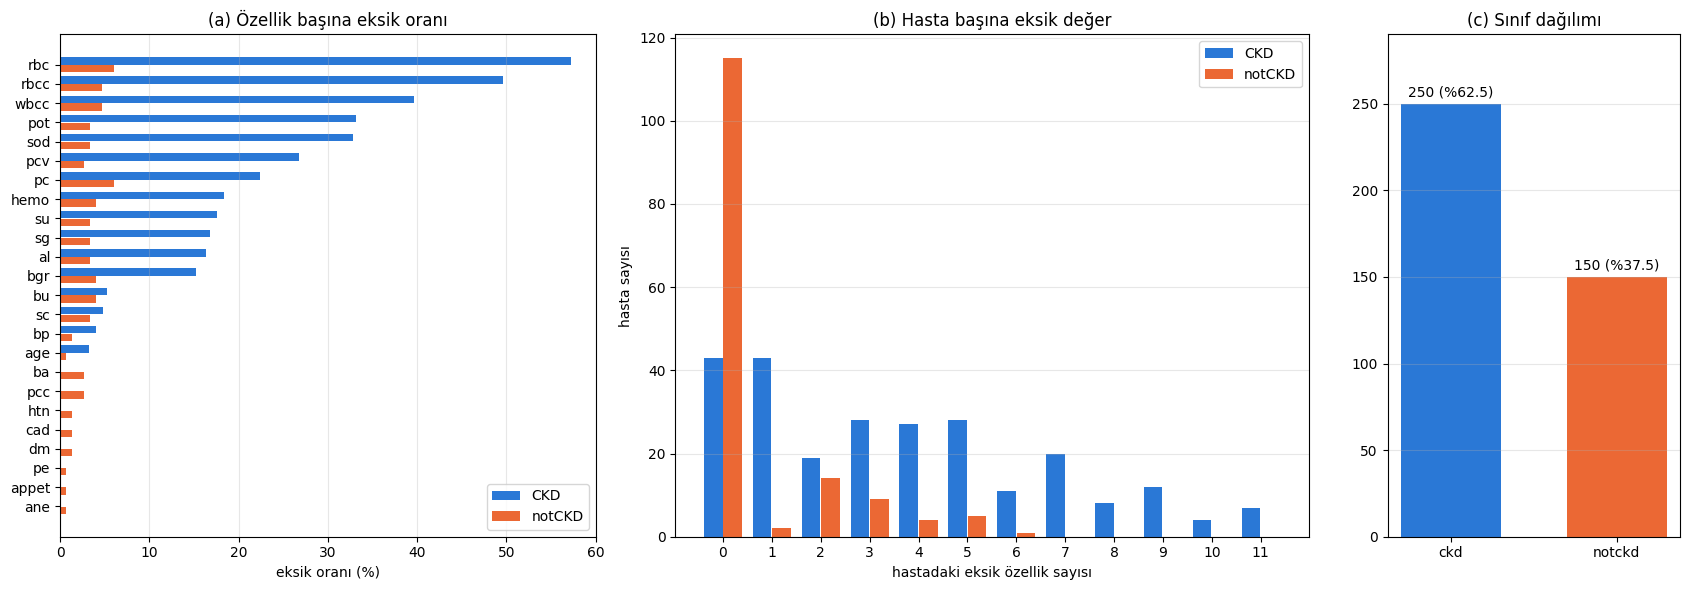

sod < 100 mEq/L: satır [21] → değer [4.5]
pot > 10 mEq/L: satır [61, 128] → değer [39.0, 47.0]
sc > 30 mg/dL: satır [21, 61, 148] → değer [76.0, 32.0, 48.1]


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 6), gridspec_kw={"width_ratios": [1.1, 1.3, 0.6]})

# (a) özellik başına eksik oranı, sınıfa göre
s = tablo.sort_values("eksik_%")
yy = np.arange(len(s))
ax[0].barh(yy + 0.2, s["eksik_%_CKD"], height=0.38, color=RENK["ckd"], label="CKD")
ax[0].barh(yy - 0.2, s["eksik_%_notCKD"], height=0.38, color=RENK["notckd"], label="notCKD")
ax[0].set_yticks(yy, s.index); ax[0].set_xlabel("eksik oranı (%)"); ax[0].set_title("(a) Özellik başına eksik oranı")
ax[0].legend(loc="lower right"); ax[0].grid(axis="x", alpha=0.3)

# (b) hasta başına eksik değer sayısı
k = np.arange(satir_eksik.max() + 1)
ax[1].bar(k - 0.2, [((satir_eksik == i) & ckd).sum() for i in k], width=0.38, color=RENK["ckd"], label="CKD")
ax[1].bar(k + 0.2, [((satir_eksik == i) & ~ckd).sum() for i in k], width=0.38, color=RENK["notckd"], label="notCKD")
ax[1].set_xticks(k); ax[1].set_xlabel("hastadaki eksik özellik sayısı"); ax[1].set_ylabel("hasta sayısı")
ax[1].set_title("(b) Hasta başına eksik değer"); ax[1].legend(); ax[1].grid(axis="y", alpha=0.3)

# (c) sınıf dağılımı
n = df["class"].value_counts()[["ckd", "notckd"]]
ax[2].bar(n.index, n.values, color=[RENK["ckd"], RENK["notckd"]], width=0.6)
for i, v in enumerate(n.values):
    ax[2].text(i, v + 4, f"{v} (%{100*v/len(df):.1f})", ha="center")
ax[2].set_title("(c) Sınıf dağılımı"); ax[2].set_ylim(0, 290); ax[2].grid(axis="y", alpha=0.3)

plt.tight_layout(); plt.savefig(f"{CIKTI}/adim1/eksiklik_ve_siniflar.png", dpi=150); plt.show()

# Klinik olarak şüpheli uç değerler (veride bırakıldı, raporda belirtilecek)
supheli = {"sod < 100 mEq/L": df["sod"] < 100, "pot > 10 mEq/L": df["pot"] > 10, "sc > 30 mg/dL": df["sc"] > 30}
for ad, m in supheli.items():
    print(f"{ad}: satır {list(df.index[m])} → değer {df.loc[m, ad.split()[0]].tolist()}")

In [7]:
from sklearn.model_selection import train_test_split

# Sabit tabakalı %70 / %15 / %15 bölme: bir kez üretilir, Drive'a kaydedilir, her deneyde aynısı kullanılır.
BOLME = f"{CIKTI}/bolme.json"
y_hepsi = ckd.astype(int).to_numpy()                  # 1 = ckd (pozitif sınıf), 0 = notckd
if not os.path.exists(BOLME):
    idx = np.arange(len(df))
    tr, gecici = train_test_split(idx, test_size=0.30, stratify=y_hepsi, random_state=42)
    va, te = train_test_split(gecici, test_size=0.50, stratify=y_hepsi[gecici], random_state=42)
    json.dump({"random_state": 42, "train": sorted(map(int, tr)), "val": sorted(map(int, va)), "test": sorted(map(int, te))},
              open(BOLME, "w"), indent=1)
bolme = json.load(open(BOLME))
TR_IDX, VA_IDX, TE_IDX = (np.array(bolme[k]) for k in ("train", "val", "test"))
assert not (set(TR_IDX) & set(VA_IDX) or set(TR_IDX) & set(TE_IDX) or set(VA_IDX) & set(TE_IDX))
assert len(TR_IDX) + len(VA_IDX) + len(TE_IDX) == len(df)

ozet = pd.DataFrame({ad: {"hasta": len(ix), "CKD": int(y_hepsi[ix].sum()), "notCKD": int((1 - y_hepsi[ix]).sum()),
                          "CKD_%": round(100 * y_hepsi[ix].mean(), 1), "eksik_hücre_%": round(100 * X_ham.iloc[ix].isna().mean().mean(), 1)}
                     for ad, ix in (("train", TR_IDX), ("val", VA_IDX), ("test", TE_IDX))}).T
ozet.to_csv(f"{CIKTI}/adim1/bolme_ozeti.csv")
print(ozet.to_string())

       hasta    CKD  notCKD  CKD_%  eksik_hücre_%
train  280.0  175.0   105.0   62.5           10.9
val     60.0   38.0    22.0   63.3           10.9
test    60.0   37.0    23.0   61.7            8.3


## 2 · Model eğitimi ve karşılaştırma (orijinal veri)

**NAIM:** Eksik değerler NaN olarak kalır, doldurma yapılmaz. Model sınıfı (`NAIM`), eğitim augmentation'ı (`missing_augmentation`) ve L1/L2 cezaları repodan **değiştirilmeden** import edilir. Repo'nun Hydra pipeline'ı yerine bu defterdeki eğitim döngüsü kullanılır, çünkü görev 5 katlı CV yerine sabit bir bölme istiyor. Döngü repo'daki `TrainManager` davranışını izler: ilk 50 epoch ısınma, validation AUC 25 epoch iyileşmezse öğrenme oranı ÷10, 50 epoch iyileşmezse durma, en iyi validation AUC'li ağırlıklarla test.

**SVM, KNN, RF:** Sayısal eksikler train medyanıyla, kategorik eksikler train'deki en sık değerle doldurulur. Sayısallar [0, 1]'e ölçeklenir, kategorikler one-hot kodlanır. Bütün istatistikler sadece train'den öğrenilir.

Her model 42, 123, 2026 seed'leriyle 3 kez eğitilir; hepsi aynı 60 test hastasında değerlendirilir. Sonuçlar ort ± ss (ddof = 1).

In [8]:
from sklearn.metrics import accuracy_score, f1_score, recall_score, roc_auc_score

METRIK = ["accuracy", "macro_f1", "recall_ckd", "recall_notckd", "auc"]
M4 = METRIK[:4]
BASLIK = {"accuracy": "Accuracy", "macro_f1": "Macro-F1", "recall_ckd": "Recall (CKD)", "recall_notckd": "Recall (notCKD)"}

def metrikler(y, olas):
    """y: 1 = ckd; olas: P(ckd). Tahmin eşiği 0,5 (= iki sınıflı softmax'ta argmax)."""
    p = (np.asarray(olas) >= 0.5).astype(int)
    return {"accuracy": accuracy_score(y, p), "macro_f1": f1_score(y, p, average="macro"),
            "recall_ckd": recall_score(y, p, pos_label=1), "recall_notckd": recall_score(y, p, pos_label=0),
            "auc": roc_auc_score(y, olas)}

def kaydet_tahmin(yol, ix, y, olas):
    pd.DataFrame({"satir": ix, "y": y, "olas_ckd": olas, "tahmin": (np.asarray(olas) >= 0.5).astype(int)}).to_csv(yol, index=False)

Y_TR, Y_VA, Y_TE = y_hepsi[TR_IDX], y_hepsi[VA_IDX], y_hepsi[TE_IDX]
os.makedirs(f"{CIKTI}/adim2/tahminler", exist_ok=True)

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

def on_isleme():
    return ColumnTransformer([
        ("sayisal", make_pipeline(SimpleImputer(strategy="median"), MinMaxScaler()), SAYISAL),
        ("kategorik", make_pipeline(SimpleImputer(strategy="most_frequent"),
                                    OneHotEncoder(categories=[SEVIYE[c] for c in KATEGORIK], handle_unknown="ignore")), KATEGORIK),
    ])

# SVM ve RF ayarları repo'daki confs/experiment/model/{svm,rf}.yaml ile aynı; KNN repoda yok, sklearn varsayılanı.
BASELINE = {
    "SVM": lambda s: SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced", probability=True, random_state=s),
    "KNN": lambda s: KNeighborsClassifier(n_neighbors=5, weights="uniform"),
    "RF":  lambda s: RandomForestClassifier(n_estimators=100, criterion="gini", class_weight="balanced", random_state=s),
}

def baseline_calistir(ad, seed, X_tr, y_tr, X_te):
    tohum(seed)
    pipe = make_pipeline(on_isleme(), BASELINE[ad](seed)).fit(X_tr, y_tr)
    return pipe.predict_proba(X_te)[:, list(pipe.classes_).index(1)], pipe

kayitlar = []
X_df = df[OZELLIK].astype({c: object for c in KATEGORIK})
for ad in BASELINE:
    for seed in SEEDLER:
        olas, pipe = baseline_calistir(ad, seed, X_df.iloc[TR_IDX], Y_TR, X_df.iloc[TE_IDX])
        kaydet_tahmin(f"{CIKTI}/adim2/tahminler/{ad}_{seed}.csv", TE_IDX, Y_TE, olas)
        kayitlar.append({"model": ad, "seed": seed, **metrikler(Y_TE, olas)})

# Train medyanları / en sık değerleri (rapor için)
doldurma = pipe[0].fit(X_df.iloc[TR_IDX])
print("train medyanları:", dict(zip(SAYISAL, doldurma.named_transformers_["sayisal"][0].statistics_)))
print("train en sık değerleri:", dict(zip(KATEGORIK, doldurma.named_transformers_["kategorik"][0].statistics_)), "\n")
print(pd.DataFrame(kayitlar).round(4).to_string())

train medyanları: {'age': np.float64(54.0), 'bp': np.float64(80.0), 'bgr': np.float64(120.0), 'bu': np.float64(44.0), 'sc': np.float64(1.3), 'sod': np.float64(138.0), 'pot': np.float64(4.3), 'hemo': np.float64(12.6), 'pcv': np.float64(40.0), 'wbcc': np.float64(8000.0), 'rbcc': np.float64(4.8)}
train en sık değerleri: {'sg': '1.020', 'al': '0', 'su': '0', 'rbc': 'normal', 'pc': 'normal', 'pcc': 'notpresent', 'ba': 'notpresent', 'htn': 'no', 'dm': 'no', 'cad': 'no', 'appet': 'good', 'pe': 'no', 'ane': 'no'} 

  model  seed  accuracy  macro_f1  recall_ckd  recall_notckd  auc
0   SVM    42    1.0000    1.0000      1.0000            1.0  1.0
1   SVM   123    1.0000    1.0000      1.0000            1.0  1.0
2   SVM  2026    1.0000    1.0000      1.0000            1.0  1.0
3   KNN    42    0.9667    0.9653      0.9459            1.0  1.0
4   KNN   123    0.9667    0.9653      0.9459            1.0  1.0
5   KNN  2026    0.9667    0.9653      0.9459            1.0  1.0
6    RF    42    0.9833  

In [10]:
# --- Repo'dan değiştirilmeden alınan parçalar ---
# CMC_utils paketinin __init__'i hydra, xgboost, pytorch-tabnet, pandarallel gibi bütün bağımlılıkları yükler.
# Bunlara gerek olmadığı için sadece ilgili dosyalar doğrudan import ediliyor.
def dosyadan_modul(ad, yol):
    spec = importlib.util.spec_from_file_location(ad, yol)
    m = importlib.util.module_from_spec(spec); spec.loader.exec_module(m); return m

sys.path.insert(0, f"{NAIM_DIR}/CMC_utils/models/tabular")
from naim import NAIM                                                         # naim/naim.py + tabular_tokenizer.py
missing_augmentation = dosyadan_modul("naim_aug", f"{NAIM_DIR}/CMC_utils/data_augmentation/tabular.py").missing_augmentation
reg = dosyadan_modul("naim_reg", f"{NAIM_DIR}/CMC_utils/regularizers/l1_l2_regularizers.py")
L1, L2 = reg.L1RegularizationLoss(), reg.L2RegularizationLoss()   # not: repodaki "L2" de Σ|w| hesaplıyor (L1 ile aynı)

# Makale (Ek B) ve confs/experiment/model/naim.yaml ayarları
NAIM_AYAR = dict(d_token=6, embedder_initialization="normal", bias=False, mask_type=2, missing_value="~inf",
                 num_heads=3, feedforward_dim=1000, dropout_rate=0.0, activation="relu", num_layers=6, extractor=False)
# confs/experiment/model_type_params/dl_params.yaml + regularizer/l1, l2 (alpha 1e-4)
EGITIM_AYAR = dict(max_epochs=1500, min_epochs=50, batch_size=32, learning_rates=[1e-3, 1e-4, 1e-5, 1e-6, 1e-7],
                   early_stopping_patience=50, scheduler_patience=25, performance_tolerance=1e-3, l1=1e-4, l2=1e-4)

CAT_IDXS = [OZELLIK.index(c) for c in KATEGORIK]
CAT_DIMS = [len(SEVIYE[c]) for c in KATEGORIK]

def naim_kodla(parca, ref):
    """Sayısal: train min/max ile [0, 1] (repo: preprocessing/numerical/normalize).
    Kategorik: ARFF seviye sırasına göre 0..c-1 tamsayı (repo: categorical_encode). Eksikler NaN kalır."""
    X = pd.DataFrame(index=parca.index)
    for c in OZELLIK:
        if c in SAYISAL:
            lo, hi = ref[c].min(), ref[c].max()
            X[c] = (parca[c] - lo) / (hi - lo)
        else:
            X[c] = parca[c].map({v: i for i, v in enumerate(SEVIYE[c])})
    return X.to_numpy(dtype=np.float32)

# Hızlı kontrol: bir batch ileri geçiş
_m = NAIM(input_size=len(OZELLIK), output_size=2, cat_idxs=CAT_IDXS, cat_dims=CAT_DIMS, **NAIM_AYAR)
_x = torch.tensor(naim_kodla(df.iloc[TR_IDX[:4]], df.iloc[TR_IDX]))
print("örnek girdi NaN sayısı:", int(torch.isnan(_x).sum()), "| çıktı:", tuple(_m(_x).shape),
      "| parametre:", sum(p.numel() for p in _m.parameters() if p.requires_grad))

örnek girdi NaN sayısı: 7 | çıktı: (4, 2) | parametre: 79778


In [11]:
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.utils.class_weight import compute_sample_weight

class TabloVeri(Dataset):
    """Repo: SupervisedTabularDatasetTorch. Augmentation açıksa her çağrıda missing_augmentation uygulanır."""
    def __init__(self, X, y, augmentation=False):
        self.X, self.y, self.aug = X, y, augmentation
        self.Y1 = np.eye(2, dtype=np.float32)[y]                    # one-hot hedef (label_type: categorical)
    def __len__(self): return len(self.X)
    def __getitem__(self, i):
        x = np.array(self.X[i], dtype=float)
        if self.aug:
            x = missing_augmentation(x.copy())
        return torch.tensor(x, dtype=torch.float32), torch.tensor(self.Y1[i])

def xavier_baslat(model):
    """Repo: models.miscellaneous.initialize_weights (xavier_uniform, yalnızca Linear katmanlar, bias = 0)."""
    for m in model.modules():
        if isinstance(m, torch.nn.Linear):
            torch.nn.init.xavier_uniform_(m.weight, gain=1.0)
            if m.bias is not None:
                torch.nn.init.zeros_(m.bias)

@torch.no_grad()
def naim_olasilik(model, X):
    model.eval()
    return torch.softmax(model(torch.tensor(X).to(CIHAZ)), dim=-1)[:, 1].cpu().numpy()

def naim_egit(X_tr, y_tr, X_va, y_va, seed, A=EGITIM_AYAR, augmentation=True):
    tohum(seed)
    model = NAIM(input_size=X_tr.shape[1], output_size=2, cat_idxs=CAT_IDXS, cat_dims=CAT_DIMS, **NAIM_AYAR)
    xavier_baslat(model); model.to(CIHAZ)
    g = torch.Generator().manual_seed(seed)
    sampler = WeightedRandomSampler(compute_sample_weight("balanced", y_tr), num_samples=len(y_tr), replacement=False, generator=g)
    yukleyici = DataLoader(TabloVeri(X_tr, y_tr, augmentation), batch_size=A["batch_size"], sampler=sampler, drop_last=True)
    ce = torch.nn.CrossEntropyLoss()
    lr_i = 0
    opt = torch.optim.Adam(model.parameters(), lr=A["learning_rates"][lr_i])
    en_iyi, en_iyi_agirlik, en_iyi_epoch, es, sch = -np.inf, copy.deepcopy(model.state_dict()), -1, 0, 0
    gecmis = []
    for epoch in range(A["max_epochs"]):
        model.train(); toplam = 0.0
        for xb, yb in yukleyici:
            xb, yb = xb.to(CIHAZ), yb.to(CIHAZ)
            opt.zero_grad()
            loss = ce(model(xb), yb) + A["l1"] * L1(model) + A["l2"] * L2(model)
            loss.backward(); opt.step(); toplam += loss.item() * len(xb)
        val_auc = roc_auc_score(y_va, naim_olasilik(model, X_va))
        gecmis.append({"epoch": epoch, "train_loss": toplam / (len(yukleyici) * A["batch_size"]), "val_auc": val_auc, "lr": A["learning_rates"][lr_i]})
        # TrainManager.callbacks: ilk min_epochs epoch'ta iyileşme sayılmaz
        if epoch > A["min_epochs"] and val_auc - en_iyi > A["performance_tolerance"]:
            en_iyi, en_iyi_agirlik, en_iyi_epoch, es, sch = val_auc, copy.deepcopy(model.state_dict()), epoch, 0, 0
        elif epoch > A["min_epochs"]:
            es += 1; sch += 1
            if sch >= A["scheduler_patience"] and lr_i < len(A["learning_rates"]) - 1:
                lr_i += 1; sch = 0
                opt = torch.optim.Adam(model.parameters(), lr=A["learning_rates"][lr_i])   # repo da optimizer'ı yeniden kuruyor
            if es >= A["early_stopping_patience"]:
                break
    model.load_state_dict(en_iyi_agirlik)
    return model, pd.DataFrame(gecmis), {"en_iyi_epoch": en_iyi_epoch, "son_epoch": epoch, "en_iyi_val_auc": en_iyi}

In [ ]:
ref = df.iloc[TR_IDX]
XN_TR, XN_VA, XN_TE = (naim_kodla(df.iloc[ix], ref) for ix in (TR_IDX, VA_IDX, TE_IDX))
os.makedirs(f"{CIKTI}/adim2/naim", exist_ok=True)

naim_kayit = []
for seed in SEEDLER:
    t0 = time.time()
    model, gecmis, bilgi = naim_egit(XN_TR, Y_TR, XN_VA, Y_VA, seed)
    olas = naim_olasilik(model, XN_TE)
    kaydet_tahmin(f"{CIKTI}/adim2/tahminler/NAIM_{seed}.csv", TE_IDX, Y_TE, olas)
    gecmis.to_csv(f"{CIKTI}/adim2/naim/gecmis_{seed}.csv", index=False)
    torch.save(model.state_dict(), f"{CIKTI}/adim2/naim/naim_{seed}.pth")
    naim_kayit.append({"model": "NAIM", "seed": seed, **metrikler(Y_TE, olas), **bilgi, "sure_sn": round(time.time() - t0)})
    print(naim_kayit[-1], flush=True)
pd.DataFrame(naim_kayit).round(4)

{'model': 'NAIM', 'seed': 42, 'accuracy': 0.9833333333333333, 'macro_f1': 0.9825123870591663, 'recall_ckd': 0.972972972972973, 'recall_notckd': 1.0, 'auc': np.float64(1.0), 'en_iyi_epoch': 51, 'son_epoch': 101, 'en_iyi_val_auc': np.float64(1.0), 'sure_sn': 39}
{'model': 'NAIM', 'seed': 123, 'accuracy': 1.0, 'macro_f1': 1.0, 'recall_ckd': 1.0, 'recall_notckd': 1.0, 'auc': np.float64(1.0), 'en_iyi_epoch': 51, 'son_epoch': 101, 'en_iyi_val_auc': np.float64(1.0), 'sure_sn': 38}
{'model': 'NAIM', 'seed': 2026, 'accuracy': 0.9833333333333333, 'macro_f1': 0.9825123870591663, 'recall_ckd': 0.972972972972973, 'recall_notckd': 1.0, 'auc': np.float64(1.0), 'en_iyi_epoch': 51, 'son_epoch': 101, 'en_iyi_val_auc': np.float64(1.0), 'sure_sn': 37}


,model,seed,accuracy,macro_f1,recall_ckd,recall_notckd,auc,en_iyi_epoch,son_epoch,en_iyi_val_auc,sure_sn
0,NAIM,42,0.9833,0.9825,0.973,1.0,1.0,51,101,1.0,39
1,NAIM,123,1.0000,1.0000,1.000,1.0,1.0,51,101,1.0,38
2,NAIM,2026,0.9833,0.9825,0.973,1.0,1.0,51,101,1.0,37


           accuracy       macro_f1     recall_ckd  recall_notckd            auc
NAIM  0.989 ± 0.010  0.988 ± 0.010  0.982 ± 0.016  1.000 ± 0.000  1.000 ± 0.000
SVM   1.000 ± 0.000  1.000 ± 0.000  1.000 ± 0.000  1.000 ± 0.000  1.000 ± 0.000
KNN   0.967 ± 0.000  0.965 ± 0.000  0.946 ± 0.000  1.000 ± 0.000  1.000 ± 0.000
RF    0.989 ± 0.010  0.988 ± 0.010  0.982 ± 0.016  1.000 ± 0.000  1.000 ± 0.000

Yanlış sınıflanan test hastaları:
  satır 1 | gerçek: ckd | eksik özellik: 5 | KNN/42 (P(ckd)=0.40), KNN/123 (P(ckd)=0.40), KNN/2026 (P(ckd)=0.40)
  satır 102 | gerçek: ckd | eksik özellik: 2 | RF/42 (P(ckd)=0.45), RF/123 (P(ckd)=0.48)
  satır 185 | gerçek: ckd | eksik özellik: 4 | NAIM/42 (P(ckd)=0.49), NAIM/2026 (P(ckd)=0.45), KNN/42 (P(ckd)=0.40), KNN/123 (P(ckd)=0.40), KNN/2026 (P(ckd)=0.40)


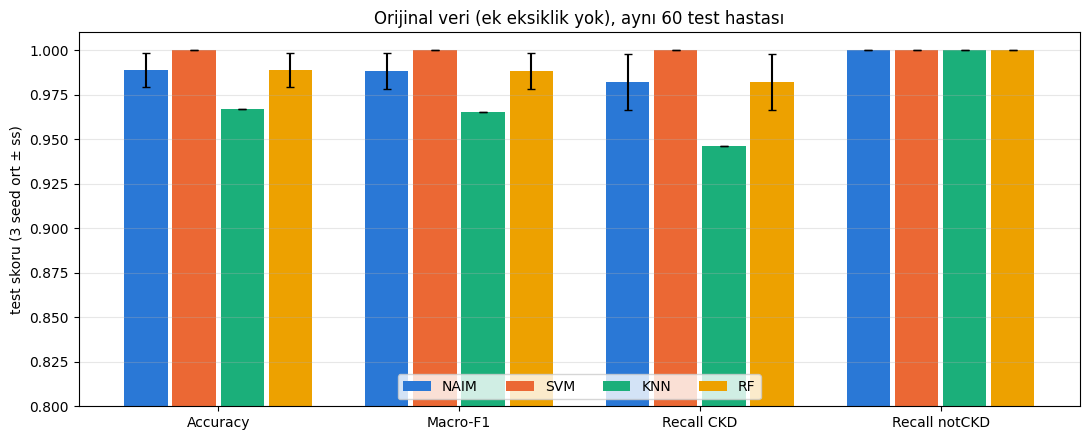

In [ ]:
METRIK = ["accuracy", "macro_f1", "recall_ckd", "recall_notckd", "auc"]
sonuc = pd.DataFrame(kayitlar + [{k: r[k] for k in ["model", "seed"] + METRIK} for r in naim_kayit])
sonuc.to_csv(f"{CIKTI}/adim2/sonuclar_seed_bazinda.csv", index=False)

sira = ["NAIM", "SVM", "KNN", "RF"]
ozet2 = sonuc.groupby("model")[METRIK].agg(["mean", "std"]).loc[sira]       # std: ddof = 1
tablo2 = pd.DataFrame({m: [f"{ozet2.loc[i, (m, 'mean')]:.3f} ± {ozet2.loc[i, (m, 'std')]:.3f}" for i in sira] for m in METRIK}, index=sira)
tablo2.to_csv(f"{CIKTI}/adim2/sonuc_tablosu.csv")
print(tablo2.to_string())

# Hangi test hastaları yanlış sınıflandırıldı?
yanlis = {}
for ad in sira:
    for seed in SEEDLER:
        t = pd.read_csv(f"{CIKTI}/adim2/tahminler/{ad}_{seed}.csv")
        for _, r in t[t.y != t.tahmin].iterrows():
            yanlis.setdefault(int(r.satir), []).append(f"{ad}/{seed} (P(ckd)={r.olas_ckd:.2f})")
print("\nYanlış sınıflanan test hastaları:")
for s, l in sorted(yanlis.items()):
    print(f"  satır {s} | gerçek: {df.loc[s, 'class']} | eksik özellik: {int(satir_eksik[s])} | {', '.join(l)}")

fig, ax = plt.subplots(figsize=(11, 4.5))
w = 0.2
for k, m in enumerate(sira):
    ort = [ozet2.loc[m, (x, "mean")] for x in METRIK[:4]]; ss = [ozet2.loc[m, (x, "std")] for x in METRIK[:4]]
    ax.bar(np.arange(4) + (k - 1.5) * w, ort, w * 0.9, yerr=ss, capsize=3, label=m, color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100"][k])
ax.set_xticks(np.arange(4), ["Accuracy", "Macro-F1", "Recall CKD", "Recall notCKD"])
ax.set_ylim(0.8, 1.01); ax.set_ylabel("test skoru (3 seed ort ± ss)"); ax.grid(axis="y", alpha=0.3)
ax.legend(ncol=4, loc="lower center"); ax.set_title("Orijinal veri (ek eksiklik yok), aynı 60 test hastası")
plt.tight_layout(); plt.savefig(f"{CIKTI}/adim2/karsilastirma.png", dpi=150); plt.show()

### Adım 2 sonuçlarının yorumu

| Model | Accuracy | Macro-F1 | Recall CKD | Recall notCKD | AUC |
|---|---|---|---|---|---|
| NAIM (repo protokolü) | 0,989 ± 0,010 | 0,988 ± 0,010 | 0,982 ± 0,016 | 1,000 ± 0,000 | 1,000 ± 0,000 |
| NAIM (uyarlanmış protokol)* | 1,000 ± 0,000 | 1,000 ± 0,000 | 1,000 ± 0,000 | 1,000 ± 0,000 | 1,000 ± 0,000 |
| SVM | 1,000 ± 0,000 | 1,000 ± 0,000 | 1,000 ± 0,000 | 1,000 ± 0,000 | 1,000 ± 0,000 |
| KNN | 0,967 ± 0,000 | 0,965 ± 0,000 | 0,946 ± 0,000 | 1,000 ± 0,000 | 1,000 ± 0,000 |
| RF | 0,989 ± 0,010 | 0,988 ± 0,010 | 0,982 ± 0,016 | 1,000 ± 0,000 | 1,000 ± 0,000 |

\* Uyarlanmış protokol (ısınma ve sabır süreleri ×6) Adım 3'ten sonra, Tanı bölümündeki bulgular üzerine eklendi; sonuçları defterin sonundaki final tabloda.

- **Veri neredeyse tamamen ayrılabilir.** Bütün modellerin AUC'si 1,0: her model hastaları doğru sıralıyor; hatalar yalnızca 0,5 eşiğinin hangi tarafına düşüldüğüyle ilgili (yanlış tahminlerde P(ckd) 0,40–0,49).
- **Farklar 1–2 hastadan ibaret.** 60 hastalık test setinde 1 hata accuracy'de 1,67 puan. KNN her seed'de aynı 2 hastayı kaçırıyor (rastgelelik içermediği için ss = 0). Bu farklar istatistiksel bir üstünlük göstermez.
- **Bütün hatalar yanlış negatif.** Hiçbir sağlıklı hasta CKD denmedi; kaçırılan 3 hasta (satır 1, 102, 185) 7, 17 ve 4 yaşında, serum kreatinin 0,6–2,1, anemi / hipertansiyon / diyabet yok: yetişkin ağırlıklı veride atipik CKD örnekleri.
- **Repo protokolünde early stopping ölçütü doydu.** Validation AUC ilk epoch'larda 1,0'a ulaştı; iyileşme ancak 50. epoch'tan sonra sayıldığı için her seed'de 51. epoch'taki ağırlıklar seçildi ve eğitim 101. epoch'ta durdu. Bu, uyarlanmış protokolün çıkış noktası oldu.

### Kullanılan ayarlar ve repoya göre farklar

**NAIM** (makale Ek B + `confs/experiment/model/naim.yaml`): d_token 6, 6 encoder katmanı, 3 dikkat başı, FF 1000, dropout 0, embedding bias yok, `mask_type: 2`, `missing_value: "~inf"` (−1e9). Ortak eğitim ayarları (`dl_params.yaml`): Adam, lr 1e-3 → 1e-7 (her adımda ÷10), batch 32, en fazla 1500 epoch, validation AUC ile model seçimi (tolerans 1e-3), cross-entropy + 1e-4·L1 + 1e-4·L2, Xavier-uniform başlatma (Linear katmanlar), sınıf dengeli örnekleme, train'de `missing_augmentation`. Parametre sayısı: 79.778.

| Protokol | Isınma | lr düşürme sabrı | Early stopping sabrı |
|---|---|---|---|
| NAIM (repo) | 50 epoch | 25 | 50 |
| NAIM (uyarlanmış) | 300 epoch | 150 | 300 |

Uyarlama gerekçesi: epoch başına güncelleme adımı makalenin en küçük veri setinde ≈ 51, CKD'de 8 (oran ≈ 6,4) → süreler ×6.

**SVM:** RBF, C = 1, gamma = "scale", class_weight = "balanced" (repo `svm.yaml`). **RF:** 100 ağaç, gini, class_weight = "balanced" (repo `rf.yaml`). **KNN:** k = 5, uniform ağırlık (repoda yok; sklearn varsayılanı). Baseline'larda hiperparametre ayarı yapılmadı; validation seti kullanılmadı. Önişleme: sayısal → train medyanı + [0,1] ölçekleme; kategorik → train'de en sık değer + one-hot.

**Kaynak kodda değişiklik yok.** `NAIM` sınıfı (`CMC_utils/models/tabular/naim/`), `missing_augmentation` (`CMC_utils/data_augmentation/tabular.py`) ve L1/L2 cezaları (`CMC_utils/regularizers/l1_l2_regularizers.py`) commit `2f15af8`'den olduğu gibi import edildi. Repo'nun Hydra pipeline'ı kullanılmadı; yerine bu defterdeki eğitim döngüsü yazıldı. Sebepler:
- Görev sabit bir 70/15/15 bölme istiyor; pipeline 5 katlı CV + holdout kullanıyor.
- Repo'daki `MCAR_global` toplam hedef oran kullanıyor ve validation'ı maskelemiyor; görev gözlenen değerlerin ek %X'ini her sette istiyor.
- CKD için repoda veri seti tanımı ve KNN sınıflandırıcı yok; doldurma ayarı (`simple.yaml`) tüm sütunlarda ortalama kullanıyor, görev medyan / en sık değer istiyor.
- `CMC_utils` paketinin tamamı import edilince hydra, xgboost, pytorch-tabnet, pandarallel gibi eski sürümlere sabitlenmiş bağımlılıklar gerekiyor.

**Repo davranışına dair notlar:** `L2RegularizationLoss` Σw² değil Σ|w| hesaplıyor (L1 ile aynı); repo'yu izlemek için olduğu gibi kullanıldı. Makalede augmentation'da maskelenen değer sayısı k ∈ {1, …, n−1}; kodda k ∈ {1, …, n−2}.

**Donanım:** Colab T4 GPU.

## 3 · Farklı eksiklik oranlarında değerlendirme

Train, validation ve test setlerinin her birinde, **gözlenen** (zaten eksik olmayan) hücrelerin ek olarak %10, %30 ve %50'si rastgele gizlenir (MCAR). Bu, repo'daki `MCAR_global`'dan farklı: orada `missing_fraction` toplam hedef oran ve zaten eksik olan hücreler sayılıyor; CKD'de doğal eksiklik ≈%10,5 olduğu için repo ile "%10" neredeyse hiç hücre gizlemezdi.

- Maskeler her (seed, oran) için `np.random.default_rng([seed, oran])` ile **bir kez** üretilir ve diske kaydedilir; bütün modeller aynı maskeyi okur. (NAIM'in augmentation'ı global `np.random`'u kullandığı için maskeyi model eğitimi sırasında üretmek, modeller arasında farklı maske verirdi.)
- Bir hastanın bütün değerleri gizlenirse o hastaya rastgele bir değeri geri verilir (her hastada en az 1 gözlenen değer kalır).
- Her oran için modeller sıfırdan eğitilir. Baseline'ların medyan / en sık değer istatistikleri ve NAIM'in min-max sınırları maskelenmiş train setinden öğrenilir.
- Ek eksiklik "%0" koşulu Adım 2'nin sonuçlarıdır.

In [12]:
ORANLAR = [10, 30, 50]                       # gözlenen hücrelerin ek % kaçı gizlenecek
MASKE_DIR = f"{CIKTI}/adim3/maskeler"
os.makedirs(MASKE_DIR, exist_ok=True)
SETLER = {"train": TR_IDX, "val": VA_IDX, "test": TE_IDX}

def ek_maske(X, oran, rng):
    """X: DataFrame (NaN = zaten eksik). Gözlenen hücrelerin `oran` kadarını gizleyen bool maske döndürür."""
    gozlenen = X.notna().to_numpy()
    konum = np.argwhere(gozlenen)
    k = int(round(oran * len(konum)))
    sec = konum[rng.choice(len(konum), size=k, replace=False)]
    M = np.zeros(X.shape, dtype=bool)
    M[sec[:, 0], sec[:, 1]] = True
    for i in np.where((gozlenen & ~M).sum(axis=1) == 0)[0]:   # tamamen boşalan hastaya bir değer geri ver
        M[i, rng.choice(np.where(M[i])[0])] = False
    return M

def maske_yolu(ad, pct, seed):
    return f"{MASKE_DIR}/{ad}_{pct}_{seed}.npy"

ozet_m = []
for seed in SEEDLER:
    for pct in ORANLAR:
        rng = np.random.default_rng([seed, pct])
        for ad, ix in SETLER.items():
            yol = maske_yolu(ad, pct, seed)
            Xs = X_ham.iloc[ix]
            if not os.path.exists(yol):
                np.save(yol, ek_maske(Xs, pct / 100, rng))
            M = np.load(yol)
            gozlenen = int(Xs.notna().to_numpy().sum())
            sonra = Xs.mask(M)
            assert not (Xs.isna().to_numpy() & M).any()              # sadece gözlenen hücreler gizlendi
            assert sonra.notna().any(axis=1).all()                    # her hastada en az 1 değer
            if ad == "train":
                assert sonra.notna().any(axis=0).all()                # her özellik train'de en az 1 kez gözlendi
            ozet_m.append({"seed": seed, "ek_%": pct, "set": ad, "gözlenen": gozlenen, "gizlenen": int(M.sum()),
                           "gizlenen_/_gözlenen_%": round(100 * M.sum() / gozlenen, 1),
                           "toplam_eksik_%": round(100 * sonra.isna().to_numpy().mean(), 1),
                           "en_az_değerli_hasta": int(sonra.notna().sum(axis=1).min())})
ozet_m = pd.DataFrame(ozet_m)
ozet_m.to_csv(f"{CIKTI}/adim3/maske_ozeti.csv", index=False)
print(ozet_m.groupby(["ek_%", "set"])[["gizlenen_/_gözlenen_%", "toplam_eksik_%", "en_az_değerli_hasta"]]
      .agg({"gizlenen_/_gözlenen_%": "mean", "toplam_eksik_%": "mean", "en_az_değerli_hasta": "min"}).round(1).to_string())

def maskeli(ad, pct, seed):
    """Seçilen setin ek maske uygulanmış ham tablosu (pct = 0 → orijinal)."""
    Xs = df[OZELLIK].iloc[SETLER[ad]]
    return Xs if pct == 0 else Xs.mask(np.load(maske_yolu(ad, pct, seed)))

            gizlenen_/_gözlenen_%  toplam_eksik_%  en_az_değerli_hasta
ek_% set                                                              
10   test                    10.0            17.5                   13
     train                   10.0            19.8                   10
     val                     10.0            19.8                   11
30   test                    30.0            35.8                    9
     train                   30.0            37.7                    5
     val                     30.0            37.6                    7
50   test                    50.0            54.2                    3
     train                   50.0            55.5                    3
     val                     50.0            55.5                    3


In [13]:
os.makedirs(f"{CIKTI}/adim3/tahminler", exist_ok=True)
os.makedirs(f"{CIKTI}/adim3/naim", exist_ok=True)
SONUC3 = f"{CIKTI}/adim3/sonuclar_seed_bazinda.csv"     # her koşu bitince bir satır eklenir (yarıda kalırsa kaldığı yerden devam)
NAIM_BILGI3 = f"{CIKTI}/adim3/naim/egitim_bilgisi.csv"
SUTUN3 = ["model", "ek_eksik", "seed"] + METRIK

def yapildi(model, pct, seed):
    if not os.path.exists(SONUC3):
        return False
    d = pd.read_csv(SONUC3)
    return bool(((d.model == model) & (d.ek_eksik == pct) & (d.seed == seed)).any())

def kayit_ekle(satir, yol=SONUC3, sutunlar=SUTUN3):
    pd.DataFrame([satir])[sutunlar].to_csv(yol, mode="a", header=not os.path.exists(yol), index=False)

# Baseline'lar: aynı maskeli train → aynı maskeli 60 test hastası
for pct in ORANLAR:
    for seed in SEEDLER:
        Xtr = maskeli("train", pct, seed).astype({c: object for c in KATEGORIK})
        Xte = maskeli("test", pct, seed).astype({c: object for c in KATEGORIK})
        for ad in BASELINE:
            if yapildi(ad, pct, seed):
                continue
            olas, _ = baseline_calistir(ad, seed, Xtr, Y_TR, Xte)
            kaydet_tahmin(f"{CIKTI}/adim3/tahminler/{ad}_{pct}_{seed}.csv", TE_IDX, Y_TE, olas)
            kayit_ekle({"model": ad, "ek_eksik": pct, "seed": seed, **metrikler(Y_TE, olas)})
print(pd.read_csv(SONUC3).groupby(["ek_eksik", "model"])[["accuracy", "macro_f1", "recall_ckd", "recall_notckd"]].mean().round(3).to_string())

                accuracy  macro_f1  recall_ckd  recall_notckd
ek_eksik model                                               
10       KNN       0.956     0.954       0.928          1.000
         NAIM      0.983     0.983       0.973          1.000
         RF        0.994     0.994       0.991          1.000
         SVM       1.000     1.000       1.000          1.000
30       KNN       0.967     0.965       0.955          0.986
         NAIM      0.961     0.959       0.955          0.971
         RF        0.989     0.988       0.991          0.986
         SVM       0.983     0.983       0.973          1.000
50       KNN       0.878     0.876       0.820          0.971
         NAIM      0.900     0.897       0.874          0.942
         RF        0.978     0.977       0.964          1.000
         SVM       0.944     0.943       0.910          1.000


In [ ]:
# Tek seferlik onarım: ilk NAIM satırı 12 sütunla yazılmıştı; ek sütunları ayrı dosyaya taşı.
import csv
satirlar_csv = list(csv.reader(open(SONUC3)))
basl = satirlar_csv[0]
duz, ekstra = [basl], []
for r in satirlar_csv[1:]:
    if len(r) > len(basl):
        ekstra.append(r[len(basl):])
        r = r[:len(basl)]
    duz.append(r)
csv.writer(open(SONUC3, "w", newline="")).writerows(duz)
if ekstra and not os.path.exists(NAIM_BILGI3):
    pd.DataFrame([{"ek_eksik": 10, "seed": 42, "en_iyi_epoch": int(e[0]), "son_epoch": int(e[1]), "en_iyi_val_auc": float(e[2]), "sure_sn": int(e[3])} for e in ekstra]).to_csv(NAIM_BILGI3, index=False)
print(pd.read_csv(SONUC3).tail(3).to_string(), "\n", pd.read_csv(NAIM_BILGI3).to_string() if os.path.exists(NAIM_BILGI3) else "")

   model  ek_eksik  seed  accuracy  macro_f1  recall_ckd  recall_notckd       auc
25   KNN        50  2026  0.883333  0.881723    0.810811            1.0  0.937720
26    RF        50  2026  0.983333  0.982512    0.972973            1.0  0.990599
27  NAIM        10    42  1.000000  1.000000    1.000000            1.0  1.000000 
    ek_eksik  seed  en_iyi_epoch  son_epoch  en_iyi_val_auc  sure_sn
0        10    42            51        101             1.0       40


In [ ]:
# NAIM: eksikler (doğal + ek) NaN olarak kalır; min-max sınırları maskeli train'den öğrenilir.
for pct in ORANLAR:
    for seed in SEEDLER:
        if yapildi("NAIM", pct, seed):
            continue
        t0 = time.time()
        Xtr, Xva, Xte = (maskeli(ad, pct, seed) for ad in ("train", "val", "test"))
        XN = [naim_kodla(X, Xtr) for X in (Xtr, Xva, Xte)]
        model, gecmis, bilgi = naim_egit(XN[0], Y_TR, XN[1], Y_VA, seed)
        olas = naim_olasilik(model, XN[2])
        kaydet_tahmin(f"{CIKTI}/adim3/tahminler/NAIM_{pct}_{seed}.csv", TE_IDX, Y_TE, olas)
        gecmis.to_csv(f"{CIKTI}/adim3/naim/gecmis_{pct}_{seed}.csv", index=False)
        torch.save(model.state_dict(), f"{CIKTI}/adim3/naim/naim_{pct}_{seed}.pth")
        kayit_ekle({"model": "NAIM", "ek_eksik": pct, "seed": seed, **metrikler(Y_TE, olas)})
        b = {"ek_eksik": pct, "seed": seed, "en_iyi_epoch": bilgi["en_iyi_epoch"], "son_epoch": bilgi["son_epoch"],
             "en_iyi_val_auc": round(float(bilgi["en_iyi_val_auc"]), 4), "sure_sn": round(time.time() - t0)}
        kayit_ekle(b, NAIM_BILGI3, list(b))
        print(f"NAIM ek %{pct} seed {seed}: acc {metrikler(Y_TE, olas)['accuracy']:.3f} | en iyi epoch {b['en_iyi_epoch']}, "
              f"son {b['son_epoch']}, val AUC {b['en_iyi_val_auc']:.4f} | {b['sure_sn']} sn", flush=True)
print("NAIM koşuları bitti")
print(pd.read_csv(NAIM_BILGI3).to_string())

NAIM ek %10 seed 123: acc 0.967 | en iyi epoch 51, son 101, val AUC 1.0000 | 39 sn
NAIM ek %10 seed 2026: acc 0.983 | en iyi epoch 71, son 121, val AUC 1.0000 | 49 sn
NAIM ek %30 seed 42: acc 0.967 | en iyi epoch 92, son 142, val AUC 0.9988 | 55 sn
NAIM ek %30 seed 123: acc 0.967 | en iyi epoch 51, son 101, val AUC 1.0000 | 40 sn
NAIM ek %30 seed 2026: acc 0.950 | en iyi epoch 55, son 105, val AUC 1.0000 | 41 sn
NAIM ek %50 seed 42: acc 0.900 | en iyi epoch 54, son 104, val AUC 0.9629 | 41 sn
NAIM ek %50 seed 123: acc 0.867 | en iyi epoch 59, son 109, val AUC 0.9904 | 43 sn
NAIM ek %50 seed 2026: acc 0.933 | en iyi epoch 104, son 154, val AUC 0.9940 | 61 sn
NAIM koşuları bitti
   ek_eksik  seed  en_iyi_epoch  son_epoch  en_iyi_val_auc  sure_sn
0        10    42            51        101          1.0000       40
1        10   123            51        101          1.0000       39
2        10  2026            71        121          1.0000       49
3        30    42            92        142

### Ara sonuç: NAIM repo protokolüyle

Aşağıdaki iki hücre baseline'ları ve repo'nun varsayılan protokolüyle eğitilen NAIM'i karşılaştırır. Bu sonuçlar NAIM'in neden düşük çıktığını araştırmaya yol açtı (Tanı bölümü). Bütün modelleri ve uyarlanmış NAIM'i içeren final tablo ve grafik defterin sonunda.

Model Ek eksiklik      accuracy      macro_f1    recall_ckd recall_notckd
 NAIM    orijinal 0.989 ± 0.010 0.988 ± 0.010 0.982 ± 0.016 1.000 ± 0.000
 NAIM         %10 0.983 ± 0.017 0.983 ± 0.017 0.973 ± 0.027 1.000 ± 0.000
 NAIM         %30 0.961 ± 0.010 0.959 ± 0.010 0.955 ± 0.041 0.971 ± 0.050
 NAIM         %50 0.900 ± 0.033 0.897 ± 0.034 0.874 ± 0.041 0.942 ± 0.025
  SVM    orijinal 1.000 ± 0.000 1.000 ± 0.000 1.000 ± 0.000 1.000 ± 0.000
  SVM         %10 1.000 ± 0.000 1.000 ± 0.000 1.000 ± 0.000 1.000 ± 0.000
  SVM         %30 0.983 ± 0.017 0.983 ± 0.017 0.973 ± 0.027 1.000 ± 0.000
  SVM         %50 0.944 ± 0.019 0.943 ± 0.020 0.910 ± 0.031 1.000 ± 0.000
  KNN    orijinal 0.967 ± 0.000 0.965 ± 0.000 0.946 ± 0.000 1.000 ± 0.000
  KNN         %10 0.956 ± 0.010 0.954 ± 0.010 0.928 ± 0.016 1.000 ± 0.000
  KNN         %30 0.967 ± 0.017 0.965 ± 0.017 0.955 ± 0.031 0.986 ± 0.025
  KNN         %50 0.878 ± 0.042 0.876 ± 0.043 0.820 ± 0.041 0.971 ± 0.050
   RF    orijinal 0.989 ± 0.010 0.988 

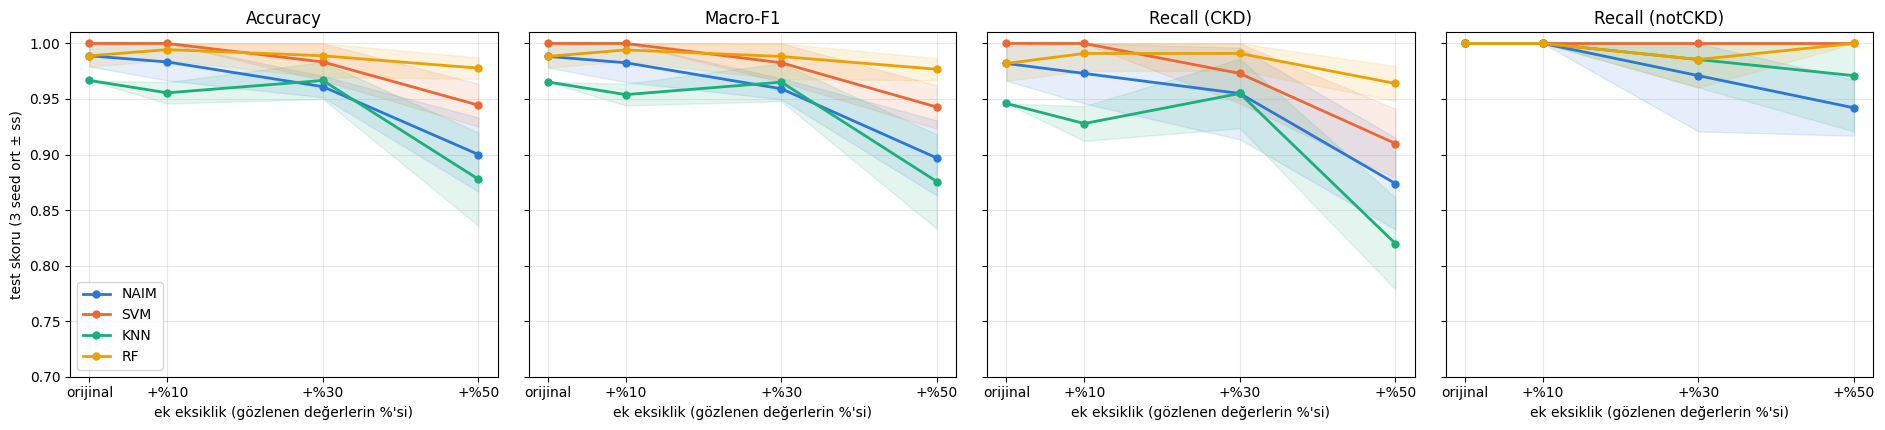

In [ ]:
M4 = ["accuracy", "macro_f1", "recall_ckd", "recall_notckd"]
s2 = pd.read_csv(f"{CIKTI}/adim2/sonuclar_seed_bazinda.csv").assign(ek_eksik=0)     # ek eksiklik %0 = Adım 2
s3 = pd.read_csv(SONUC3)
hepsi = pd.concat([s2[["model", "ek_eksik", "seed"] + METRIK], s3[["model", "ek_eksik", "seed"] + METRIK]], ignore_index=True)
assert len(hepsi) == 4 * 4 * 3, len(hepsi)
hepsi.to_csv(f"{CIKTI}/adim3/tum_sonuclar_seed_bazinda.csv", index=False)

ozet3 = hepsi.groupby(["model", "ek_eksik"])[METRIK].agg(["mean", "std"])                    # std: ddof = 1
satirlar = []
for m in sira:
    for pct in [0] + ORANLAR:
        satirlar.append({"Model": m, "Ek eksiklik": f"%{pct}" if pct else "orijinal",
                         **{k: f"{ozet3.loc[(m, pct), (k, 'mean')]:.3f} ± {ozet3.loc[(m, pct), (k, 'std')]:.3f}" for k in M4}})
tablo3 = pd.DataFrame(satirlar)
tablo3.to_csv(f"{CIKTI}/adim3/sonuc_tablosu.csv", index=False)
print(tablo3.to_string(index=False))

# Orijinale göre düşüş (macro-F1, puan)
dusus = pd.DataFrame({m: [100 * (ozet3.loc[(m, 0), ("macro_f1", "mean")] - ozet3.loc[(m, p), ("macro_f1", "mean")]) for p in ORANLAR] for m in sira},
                     index=[f"+%{p}" for p in ORANLAR]).round(1)
print("\nMacro-F1 düşüşü (orijinale göre, puan):\n", dusus.to_string())

RENK_M = {"NAIM": "#2a78d6", "SVM": "#eb6834", "KNN": "#1baf7a", "RF": "#eda100"}
BASLIK = {"accuracy": "Accuracy", "macro_f1": "Macro-F1", "recall_ckd": "Recall (CKD)", "recall_notckd": "Recall (notCKD)"}
x = [0] + ORANLAR
fig, axs = plt.subplots(1, 4, figsize=(19, 4.4), sharey=True)
for ax, k in zip(axs, M4):
    for m in sira:
        ort = np.array([ozet3.loc[(m, p), (k, "mean")] for p in x]); ss = np.array([ozet3.loc[(m, p), (k, "std")] for p in x])
        ax.plot(x, ort, "-o", color=RENK_M[m], lw=2, ms=5, label=m)
        ax.fill_between(x, ort - ss, np.minimum(ort + ss, 1), color=RENK_M[m], alpha=0.12)
    ax.set_title(BASLIK[k]); ax.set_xticks(x, ["orijinal", "+%10", "+%30", "+%50"]); ax.grid(alpha=0.3)
    ax.set_xlabel("ek eksiklik (gözlenen değerlerin %'si)")
axs[0].set_ylabel("test skoru (3 seed ort ± ss)"); axs[0].set_ylim(0.7, 1.01); axs[0].legend(loc="lower left")
plt.tight_layout(); plt.savefig(f"{CIKTI}/adim3/performans.png", dpi=150); plt.show()

In [ ]:
# Ek analiz: AUC (eşikten bağımsız), seed bazında accuracy ve hata türleri
print("AUC (3 seed ort ± ss):")
print(pd.DataFrame({m: [f"{ozet3.loc[(m, p), ('auc', 'mean')]:.3f} ± {ozet3.loc[(m, p), ('auc', 'std')]:.3f}" for p in x] for m in sira},
                   index=["orijinal", "+%10", "+%30", "+%50"]).to_string())

print("\nSeed bazında accuracy (+%50):")
print(hepsi[hepsi.ek_eksik == 50].pivot(index="seed", columns="model", values="accuracy")[sira].round(3).to_string())

def hata_say(model, pct, seed):
    yol = f"{CIKTI}/adim2/tahminler/{model}_{seed}.csv" if pct == 0 else f"{CIKTI}/adim3/tahminler/{model}_{pct}_{seed}.csv"
    t = pd.read_csv(yol)
    return int(((t.y == 1) & (t.tahmin == 0)).sum()), int(((t.y == 0) & (t.tahmin == 1)).sum())
print("\nHata türleri, 3 seed toplamı (YN = kaçırılan CKD, YP = yanlış CKD alarmı):")
print(pd.DataFrame({m: [f"YN {sum(hata_say(m, p, s)[0] for s in SEEDLER)} / YP {sum(hata_say(m, p, s)[1] for s in SEEDLER)}" for p in x] for m in sira},
                   index=["orijinal", "+%10", "+%30", "+%50"]).to_string())
print("\nNAIM eğitim bilgisi:\n", pd.read_csv(NAIM_BILGI3).groupby("ek_eksik")[["en_iyi_epoch", "son_epoch", "en_iyi_val_auc"]].mean().round(3).to_string())

AUC (3 seed ort ± ss):
                   NAIM            SVM            KNN             RF
orijinal  1.000 ± 0.000  1.000 ± 0.000  1.000 ± 0.000  1.000 ± 0.000
+%10      1.000 ± 0.000  1.000 ± 0.000  0.995 ± 0.008  1.000 ± 0.000
+%30      0.998 ± 0.001  1.000 ± 0.000  0.992 ± 0.010  1.000 ± 0.001
+%50      0.972 ± 0.001  0.980 ± 0.009  0.944 ± 0.027  0.989 ± 0.012

Seed bazında accuracy (+%50):
model   NAIM    SVM    KNN     RF
seed                             
42     0.900  0.933  0.833  0.983
123    0.867  0.967  0.917  0.967
2026   0.933  0.933  0.883  0.983

Hata türleri, 3 seed toplamı (YN = kaçırılan CKD, YP = yanlış CKD alarmı):
                  NAIM           SVM           KNN           RF
orijinal   YN 2 / YP 0   YN 0 / YP 0   YN 6 / YP 0  YN 2 / YP 0
+%10       YN 3 / YP 0   YN 0 / YP 0   YN 8 / YP 0  YN 1 / YP 0
+%30       YN 5 / YP 2   YN 3 / YP 0   YN 5 / YP 1  YN 1 / YP 1
+%50      YN 14 / YP 4  YN 10 / YP 0  YN 20 / YP 2  YN 4 / YP 0

NAIM eğitim bilgisi:
           en

### Tanı: NAIM'in düşük skoru bir hata mı?

Repo protokolüyle NAIM +%50'de 0,900 accuracy ile RF (0,978) ve SVM'nin (0,944) gerisinde kaldı. Aşağıdaki dört hücre bunun kod hatasından mı, eğitim protokolünden mi geldiğini inceliyor:

1. **Eğitim geçmişleri:** seçilen epoch 51–104; o noktada eğitim kaybı hâlâ hızla düşüyor. Validation AUC çok erken doyduğu için early stopping erken devreye giriyor. L1 + L2 cezası başlangıçta cross-entropy kadar büyük (0,66'ya karşı 0,69).
2. **Girdi kodlaması:** NaN'lar doğru yerde, kategorik kodlar doğru; model eksik özelliği beklenen şekilde yok sayıyor.
3. **Uç değerler:** normalize değeri 7'yi aşan hasta (potasyum 47) NAIM'de doğru sınıflanıyor; hatalar başka hastalara dağılmış.
4. **400 epoch, early stopping yok (+%50):** ortalama accuracy 0,900 → 0,950, AUC 0,972 → 0,985. Test skorları yalnızca tanı için kaydedildi, model seçiminde kullanılmadı.

Sonuç: kodda hata yok; repo'nun epoch tabanlı ayarları bu veri boyutunda eğitimi erken kesiyor. Uyarlanmış protokol bir sonraki bölümde.

In [ ]:
# TANI 1: NAIM eğitim geçmişleri — seçilen epoch'ta model yeterince eğitilmiş mi?
for pct in [0, 50]:
    for seed in SEEDLER:
        yol = f"{CIKTI}/adim2/naim/gecmis_{seed}.csv" if pct == 0 else f"{CIKTI}/adim3/naim/gecmis_{pct}_{seed}.csv"
        g = pd.read_csv(yol)
        en_iyi = g.loc[g.epoch > 50, "val_auc"].idxmax()
        print(f"ek %{pct} seed {seed}: train_loss ep0 {g.train_loss[0]:.3f} → ep50 {g.train_loss[50]:.3f} → seçilen ep{en_iyi} {g.train_loss[en_iyi]:.3f} → son ep{len(g)-1} {g.train_loss.iloc[-1]:.3f}"
              f" | val_auc ep10 {g.val_auc[10]:.3f}, ep50 {g.val_auc[50]:.3f}, max {g.val_auc.max():.3f} (ep{g.val_auc.idxmax()}) | lr son {g.lr.iloc[-1]:g}")

# Kayıp bileşenleri: CE ile L1+L2 cezasının büyüklüğü (repo'daki "L2" de Σ|w|)
_m = NAIM(input_size=len(OZELLIK), output_size=2, cat_idxs=CAT_IDXS, cat_dims=CAT_DIMS, **NAIM_AYAR); xavier_baslat(_m)
print("\nbaşlangıçta Σ|w| =", round(float(L1(_m)), 1), "→ ceza 2e-4·Σ|w| =", round(2e-4 * float(L1(_m)), 3), "| CE başlangıçta ≈ ln2 = 0.693")
_m.load_state_dict(torch.load(f"{CIKTI}/adim3/naim/naim_50_42.pth", map_location="cpu"))
print("eğitilmiş (ek %50, seed 42) Σ|w| =", round(float(L1(_m)), 1), "→ ceza", round(2e-4 * float(L1(_m)), 3))

ek %0 seed 42: train_loss ep0 1.224 → ep50 0.408 → seçilen ep51 0.413 → son ep101 0.264 | val_auc ep10 1.000, ep50 1.000, max 1.000 (ep0) | lr son 0.0001
ek %0 seed 123: train_loss ep0 1.467 → ep50 0.316 → seçilen ep51 0.323 → son ep101 0.227 | val_auc ep10 1.000, ep50 1.000, max 1.000 (ep4) | lr son 0.0001
ek %0 seed 2026: train_loss ep0 1.303 → ep50 0.442 → seçilen ep51 0.407 → son ep101 0.279 | val_auc ep10 1.000, ep50 1.000, max 1.000 (ep1) | lr son 0.0001
ek %50 seed 42: train_loss ep0 1.325 → ep50 0.465 → seçilen ep54 0.465 → son ep104 0.333 | val_auc ep10 0.944, ep50 0.959, max 0.967 (ep34) | lr son 0.0001
ek %50 seed 123: train_loss ep0 1.435 → ep50 0.421 → seçilen ep59 0.418 → son ep109 0.295 | val_auc ep10 0.983, ep50 0.976, max 0.990 (ep59) | lr son 0.0001
ek %50 seed 2026: train_loss ep0 1.506 → ep50 0.489 → seçilen ep104 0.342 → son ep154 0.286 | val_auc ep10 0.946, ep50 0.978, max 0.994 (ep104) | lr son 0.0001

başlangıçta Σ|w| = 3285.4 → ceza 2e-4·Σ|w| = 0.657 | CE başla

/tmp/ipykernel_1407/2514416051.py:12: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  print("\nbaşlangıçta Σ|w| =", round(float(L1(_m)), 1), "→ ceza 2e-4·Σ|w| =", round(2e-4 * float(L1(_m)), 3), "| CE başlangıçta ≈ ln2 = 0.693")


In [ ]:
# TANI 2: NAIM girdisinin doğru kodlandığını kontrol et (+%50, seed 42)
Xtr, Xva, Xte = (maskeli(ad, 50, 42) for ad in ("train", "val", "test"))
XN = [naim_kodla(X, Xtr) for X in (Xtr, Xva, Xte)]
for ad, X, Z in zip(("train", "val", "test"), (Xtr, Xva, Xte), XN):
    assert np.array_equal(np.isnan(Z), X.isna().to_numpy())                    # NaN'lar birebir aynı yerde
    for j, c in enumerate(OZELLIK):
        v = Z[:, j][~np.isnan(Z[:, j])]
        if c in KATEGORIK:
            assert set(np.unique(v)) <= set(range(len(SEVIYE[c]))), c          # kod 0..c-1
            ham = X[c].dropna().map({s: i for i, s in enumerate(SEVIYE[c])}).to_numpy()
            assert np.array_equal(v, ham), c                                    # kod ham değerle eşleşiyor
    print(f"{ad}: NaN oranı %{100*np.isnan(Z).mean():.1f}, sayısal aralık [{np.nanmin(Z[:, [OZELLIK.index(c) for c in SAYISAL]]):.2f}, {np.nanmax(Z[:, [OZELLIK.index(c) for c in SAYISAL]]):.2f}]")
assert all(OZELLIK[i] in KATEGORIK for i in CAT_IDXS) and [OZELLIK[i] for i in CAT_IDXS] == KATEGORIK

# Eğitilmiş modelde: bir hastanın eksik özelliğine hangi değer yazılırsa yazılsın çıktı değişmemeli mi?
# NaN yerine bir değer yazmak özelliği "gözlenen" yapar; tersine, gözlenen bir değeri NaN yapınca çıktı değişmeli.
_m.to(CIHAZ).eval()
with torch.no_grad():
    x = torch.tensor(XN[2][:5]).to(CIHAZ)
    p0 = torch.softmax(_m(x), -1)[:, 1]
    x2 = x.clone(); j = OZELLIK.index("hemo"); x2[:, j] = float("nan")
    p1 = torch.softmax(_m(x2), -1)[:, 1]
print("P(ckd) hemo var/yok:", np.round(p0.cpu().numpy(), 3), np.round(p1.cpu().numpy(), 3))
print("Kodlama kontrolleri geçti.")

train: NaN oranı %55.5, sayısal aralık [0.00, 1.00]
val: NaN oranı %55.5, sayısal aralık [0.00, 1.00]
test: NaN oranı %54.2, sayısal aralık [-0.05, 7.16]
P(ckd) hemo var/yok: [0.176 1.    0.94  0.842 0.927] [0.15  1.    0.9   0.842 0.927]
Kodlama kontrolleri geçti.


In [ ]:
# TANI 3: +%50'de hangi test hastaları yanlış? Uç değerli (normalize > 1.5) hastalar mı?
satir = []
for s_i, s in enumerate(TE_IDX):
    r = {"satir": int(s), "sinif": df.loc[s, "class"], "yas": df.loc[s, "age"]}
    for seed in SEEDLER:
        Xtr_ = maskeli("train", 50, seed)
        z = naim_kodla(maskeli("test", 50, seed), Xtr_)[s_i]
        r[f"max_z_{seed}"] = round(float(np.nanmax(np.abs(z[[OZELLIK.index(c) for c in SAYISAL]]))), 2)
    for m in sira:
        r[m] = sum(int(pd.read_csv(f"{CIKTI}/adim3/tahminler/{m}_50_{seed}.csv").set_index("satir").loc[s].pipe(lambda t: t.y != t.tahmin)) for seed in SEEDLER)
    satir.append(r)
h = pd.DataFrame(satir)
yanlis50 = h[(h[sira].sum(axis=1) > 0)].sort_values("NAIM", ascending=False)
print("+%50'de en az bir modelin yanıldığı hastalar (sütunlar: 3 seed'de kaç kez yanlış):")
print(yanlis50.to_string(index=False))
print("\nNormalize değeri 1.5'i aşan test hastaları:", h.loc[h[[f"max_z_{s}" for s in SEEDLER]].max(axis=1) > 1.5, "satir"].tolist())
for c in ["sc", "pot", "sod", "bu", "bgr", "wbcc"]:
    print(f"  {c}: train max {df[c].iloc[TR_IDX].max():g} | test max {df[c].iloc[TE_IDX].max():g}")

+%50'de en az bir modelin yanıldığı hastalar (sütunlar: 3 seed'de kaç kez yanlış):
 satir  sinif  yas  max_z_42  max_z_123  max_z_2026  NAIM  SVM  KNN  RF
   150    ckd  8.0      0.71       0.73        0.71     3    1    1   1
     1    ckd  7.0      0.56       0.66        0.64     2    1    2   0
   102    ckd 17.0      0.96       0.98        0.96     2    3    3   2
   115    ckd 47.0      0.78       0.80        0.59     1    0    1   1
   146    ckd 53.0      0.92       0.76        0.41     1    0    1   0
    35    ckd 65.0      0.53       0.64        0.61     1    0    0   0
   352 notckd 37.0      0.94       0.80        0.80     1    0    0   0
   338 notckd 62.0      1.00       1.02        0.80     1    0    0   0
   179    ckd 72.0      0.88       0.68        0.94     1    1    2   0
   183    ckd 30.0      0.42       0.27        0.35     1    1    0   0
   324 notckd 40.0      0.02       0.23        1.00     1    0    1   0
   308 notckd 43.0      0.87       0.43        0.73  

In [ ]:
# TANI 4: +%50'de NAIM'i early stopping olmadan 400 epoch eğit; öğrenme eğrisini kaydet.
# Test skorları SADECE tanı için kaydediliyor; model seçiminde kullanılmıyor.
def naim_egri(X_tr, y_tr, X_va, y_va, X_te, y_te, seed, epoch_sayisi=400, augmentation=True, lr=1e-3):
    tohum(seed)
    model = NAIM(input_size=X_tr.shape[1], output_size=2, cat_idxs=CAT_IDXS, cat_dims=CAT_DIMS, **NAIM_AYAR)
    xavier_baslat(model); model.to(CIHAZ)
    g = torch.Generator().manual_seed(seed)
    sampler = WeightedRandomSampler(compute_sample_weight("balanced", y_tr), num_samples=len(y_tr), replacement=False, generator=g)
    yukleyici = DataLoader(TabloVeri(X_tr, y_tr, augmentation), batch_size=32, sampler=sampler, drop_last=True)
    ce = torch.nn.CrossEntropyLoss(); opt = torch.optim.Adam(model.parameters(), lr=lr)
    kayit = []
    for epoch in range(epoch_sayisi):
        model.train()
        for xb, yb in yukleyici:
            xb, yb = xb.to(CIHAZ), yb.to(CIHAZ); opt.zero_grad()
            (ce(model(xb), yb) + 1e-4 * L1(model) + 1e-4 * L2(model)).backward(); opt.step()
        if epoch % 10 == 9:
            pv, pt = naim_olasilik(model, X_va), naim_olasilik(model, X_te)
            val_ce = float(-np.mean(np.log(np.clip(np.where(y_va == 1, pv, 1 - pv), 1e-7, 1))))
            kayit.append({"epoch": epoch + 1, "val_auc": roc_auc_score(y_va, pv), "val_ce": val_ce,
                          "test_acc": accuracy_score(y_te, pt >= 0.5), "test_auc": roc_auc_score(y_te, pt)})
    return pd.DataFrame(kayit)

egriler = {}
for seed in SEEDLER:
    Xtr, Xva, Xte = (maskeli(ad, 50, seed) for ad in ("train", "val", "test"))
    XN = [naim_kodla(X, Xtr) for X in (Xtr, Xva, Xte)]
    t0 = time.time()
    egriler[seed] = naim_egri(XN[0], Y_TR, XN[1], Y_VA, XN[2], Y_TE, seed)
    egriler[seed].to_csv(f"{CIKTI}/adim3/naim/tani_egri_50_{seed}.csv", index=False)
    print(f"seed {seed} bitti ({time.time() - t0:.0f} sn)", flush=True)
for seed, e in egriler.items():
    print(f"\nseed {seed}:\n", e.iloc[[0, 4, 9, 14, 19, 29, 39]].round(3).to_string(index=False))

seed 42 bitti (140 sn)
seed 123 bitti (140 sn)
seed 2026 bitti (140 sn)

seed 42:
  epoch  val_auc  val_ce  test_acc  test_auc
    10    0.957   0.291     0.883     0.961
    50    0.955   0.261     0.917     0.972
   100    0.963   0.286     0.917     0.972
   150    0.961   0.266     0.950     0.978
   200    0.964   0.342     0.967     0.975
   300    0.977   0.273     0.967     0.979
   400    0.984   0.188     0.967     0.986

seed 123:
  epoch  val_auc  val_ce  test_acc  test_auc
    10    0.971   0.261     0.867     0.945
    50    0.986   0.174     0.917     0.986
   100    0.981   0.175     0.933     0.991
   150    0.987   0.158     0.967     0.992
   200    0.992   0.163     0.950     0.991
   300    0.992   0.191     0.950     0.989
   400    0.995   0.165     0.967     0.995

seed 2026:
  epoch  val_auc  val_ce  test_acc  test_auc
    10    0.947   0.363     0.833     0.899
    50    0.983   0.231     0.917     0.964
   100    0.989   0.226     0.883     0.967
   150    0.

### NAIM: veri boyutuna uyarlanmış eğitim protokolü

Tanı deneyleri (TANI 1–4) kodda bir hata göstermedi; ama repo'nun epoch tabanlı early stopping ayarları bu veri setinde NAIM'i çok erken durduruyor. 60 hastalık validation setinde AUC hızla doyuyor; sonraki küçük iyileşmeler 50 epoch içinde 1e-3 eşiğini geçemiyor ve model ≈50–100. epoch'ta seçiliyor (eğitim kaybı hâlâ düşerken).

Repo ayarları büyük veri setleri için yazılmış. Ayarlar epoch cinsinden olduğu için, aynı sayıda epoch küçük veride çok daha az güncelleme adımı demek:

| | train hasta | batch | adım / epoch |
|---|---|---|---|
| Makalenin en küçük veri seti (SeismicBumps) | 2584 × 0,8 × 0,8 ≈ 1654 | 32 | ≈ 51 |
| CKD (bu çalışma) | 280 | 32 | 8 (`drop_last`) |

Oran ≈ 6,4. Isınma ve sabır süreleri **adım sayısını eşitlemek için 6 ile çarpıldı**: ısınma 50 → 300 epoch, lr düşürme sabrı 25 → 150, early stopping sabrı 50 → 300. Diğer her şey (mimari, kayıp, L1/L2, augmentation, Adam, lr dizisi, en fazla 1500 epoch, validation AUC ile seçim) aynı.

**Not:** Bu uyarlama, repo varsayılanının sonuçları ve tanı deneyindeki eğriler görüldükten sonra yapıldı; gerekçesi test skoru değil adım sayısı. Tabloda iki NAIM satırı birlikte raporlanır: **NAIM (repo)** = varsayılan protokol, **NAIM (uyarlanmış)** = bu protokol. Baseline'lar değişmedi.

In [15]:
OLCEK = 6
EGITIM_AYAR_U = {**EGITIM_AYAR, "min_epochs": 50 * OLCEK, "scheduler_patience": 25 * OLCEK, "early_stopping_patience": 50 * OLCEK}
print({k: EGITIM_AYAR_U[k] for k in ("max_epochs", "min_epochs", "scheduler_patience", "early_stopping_patience")})

U_DIR = f"{CIKTI}/adim3/naim_uyarlanmis"
os.makedirs(U_DIR, exist_ok=True)
SONUC_U = f"{U_DIR}/sonuclar_seed_bazinda.csv"
BILGI_U = f"{U_DIR}/egitim_bilgisi.csv"

def yapildi_u(pct, seed):
    if not os.path.exists(SONUC_U):
        return False
    d = pd.read_csv(SONUC_U)
    return bool(((d.ek_eksik == pct) & (d.seed == seed)).any())

for pct in [0] + ORANLAR:
    for seed in SEEDLER:
        if yapildi_u(pct, seed):
            continue
        t0 = time.time()
        Xtr, Xva, Xte = (maskeli(ad, pct, seed) for ad in ("train", "val", "test"))
        XN = [naim_kodla(X, Xtr) for X in (Xtr, Xva, Xte)]
        model, gecmis, bilgi = naim_egit(XN[0], Y_TR, XN[1], Y_VA, seed, A=EGITIM_AYAR_U)
        olas = naim_olasilik(model, XN[2])
        kaydet_tahmin(f"{U_DIR}/tahmin_{pct}_{seed}.csv", TE_IDX, Y_TE, olas)
        gecmis.to_csv(f"{U_DIR}/gecmis_{pct}_{seed}.csv", index=False)
        torch.save(model.state_dict(), f"{U_DIR}/naim_{pct}_{seed}.pth")
        kayit_ekle({"model": "NAIM (uyarlanmış)", "ek_eksik": pct, "seed": seed, **metrikler(Y_TE, olas)}, SONUC_U)
        b = {"ek_eksik": pct, "seed": seed, "en_iyi_epoch": bilgi["en_iyi_epoch"], "son_epoch": bilgi["son_epoch"],
             "en_iyi_val_auc": round(float(bilgi["en_iyi_val_auc"]), 4), "sure_sn": round(time.time() - t0)}
        kayit_ekle(b, BILGI_U, list(b))
        print(f"ek %{pct} seed {seed}: acc {metrikler(Y_TE, olas)['accuracy']:.3f} | en iyi epoch {b['en_iyi_epoch']}, "
              f"son {b['son_epoch']}, val AUC {b['en_iyi_val_auc']:.4f} | {b['sure_sn']} sn", flush=True)
print("Uyarlanmış NAIM koşuları bitti")
print(pd.read_csv(BILGI_U).to_string())

{'max_epochs': 1500, 'min_epochs': 300, 'scheduler_patience': 150, 'early_stopping_patience': 300}
ek %50 seed 2026: acc 0.900 | en iyi epoch 324, son 624, val AUC 1.0000 | 226 sn
Uyarlanmış NAIM koşuları bitti
    ek_eksik  seed  en_iyi_epoch  son_epoch  en_iyi_val_auc  sure_sn
0          0    42           301        601          1.0000      229
1          0   123           301        601          1.0000      222
2          0  2026           301        601          1.0000      219
3         10    42           301        601          1.0000      224
4         10   123           301        601          1.0000      226
5         10  2026           301        601          1.0000      223
6         30    42           301        601          1.0000      222
7         30   123           301        601          1.0000      223
8         30  2026           306        606          1.0000      225
9         50    42           634        934          0.9928      348
10        50   123           4

            Model Ek eksiklik      accuracy      macro_f1    recall_ckd recall_notckd           auc
NAIM (uyarlanmış)    orijinal 1.000 ± 0.000 1.000 ± 0.000 1.000 ± 0.000 1.000 ± 0.000 1.000 ± 0.000
      NAIM (repo)    orijinal 0.989 ± 0.010 0.988 ± 0.010 0.982 ± 0.016 1.000 ± 0.000 1.000 ± 0.000
              SVM    orijinal 1.000 ± 0.000 1.000 ± 0.000 1.000 ± 0.000 1.000 ± 0.000 1.000 ± 0.000
              KNN    orijinal 0.967 ± 0.000 0.965 ± 0.000 0.946 ± 0.000 1.000 ± 0.000 1.000 ± 0.000
               RF    orijinal 0.989 ± 0.010 0.988 ± 0.010 0.982 ± 0.016 1.000 ± 0.000 1.000 ± 0.000
NAIM (uyarlanmış)        +%10 1.000 ± 0.000 1.000 ± 0.000 1.000 ± 0.000 1.000 ± 0.000 1.000 ± 0.000
      NAIM (repo)        +%10 0.983 ± 0.017 0.983 ± 0.017 0.973 ± 0.027 1.000 ± 0.000 1.000 ± 0.000
              SVM        +%10 1.000 ± 0.000 1.000 ± 0.000 1.000 ± 0.000 1.000 ± 0.000 1.000 ± 0.000
              KNN        +%10 0.956 ± 0.010 0.954 ± 0.010 0.928 ± 0.016 1.000 ± 0.000 0.995 ± 0.008


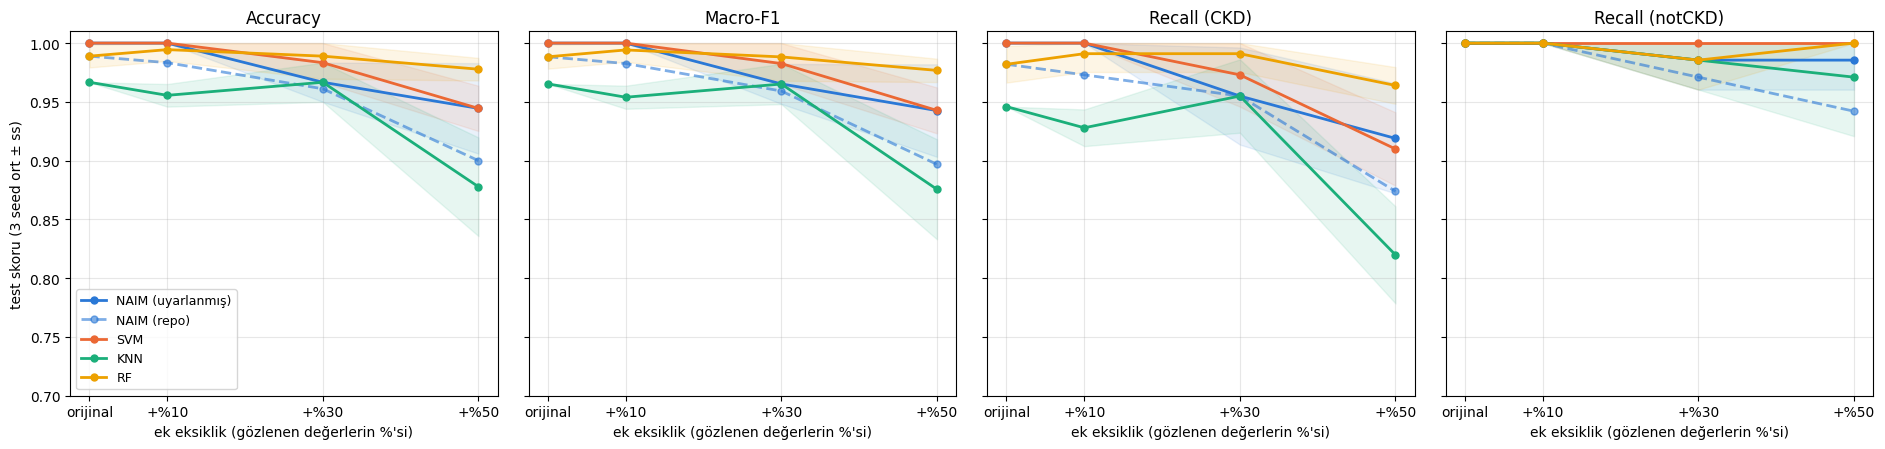

In [16]:
# FİNAL SONUÇLAR: NAIM (uyarlanmış), NAIM (repo), SVM, KNN, RF — 4 koşul × 3 seed, aynı 60 test hastası
s_repo = pd.read_csv(f"{CIKTI}/adim3/tum_sonuclar_seed_bazinda.csv").replace({"model": {"NAIM": "NAIM (repo)"}})
s_u = pd.read_csv(SONUC_U)
final = pd.concat([s_repo, s_u[s_repo.columns]], ignore_index=True)
assert len(final) == 5 * 4 * 3, len(final)
final.to_csv(f"{CIKTI}/final_sonuclar_seed_bazinda.csv", index=False)

sira5 = ["NAIM (uyarlanmış)", "NAIM (repo)", "SVM", "KNN", "RF"]
KOSUL = {0: "orijinal", 10: "+%10", 30: "+%30", 50: "+%50"}
ozet5 = final.groupby(["model", "ek_eksik"])[METRIK].agg(["mean", "std"])                   # std: ddof = 1
tablo5 = pd.DataFrame([{"Model": m, "Ek eksiklik": KOSUL[p],
                        **{k: f"{ozet5.loc[(m, p), (k, 'mean')]:.3f} ± {ozet5.loc[(m, p), (k, 'std')]:.3f}" for k in M4 + ['auc']}}
                       for p in KOSUL for m in sira5])
tablo5.to_csv(f"{CIKTI}/final_sonuc_tablosu.csv", index=False)
print(tablo5.to_string(index=False))

print("\nMacro-F1 düşüşü (orijinale göre, puan):")
print(pd.DataFrame({m: [100 * (ozet5.loc[(m, 0), ("macro_f1", "mean")] - ozet5.loc[(m, p), ("macro_f1", "mean")]) for p in ORANLAR] for m in sira5},
                   index=[KOSUL[p] for p in ORANLAR]).round(1).to_string())
print("\nUyarlanmış NAIM eğitim bilgisi (ortalama):")
print(pd.read_csv(BILGI_U).groupby("ek_eksik")[["en_iyi_epoch", "son_epoch", "en_iyi_val_auc", "sure_sn"]].mean().round(1).to_string())

STIL = {"NAIM (uyarlanmış)": ("#2a78d6", "-"), "NAIM (repo)": ("#2a78d6", "--"), "SVM": ("#eb6834", "-"),
        "KNN": ("#1baf7a", "-"), "RF": ("#eda100", "-")}
fig, axs = plt.subplots(1, 4, figsize=(19, 4.6), sharey=True)
for ax, k in zip(axs, M4):
    for m in sira5:
        ort = np.array([ozet5.loc[(m, p), (k, "mean")] for p in KOSUL]); ss = np.array([ozet5.loc[(m, p), (k, "std")] for p in KOSUL])
        renk, cizgi = STIL[m]
        ax.plot(list(KOSUL), ort, cizgi, marker="o", color=renk, lw=2, ms=5, label=m, alpha=0.6 if m == "NAIM (repo)" else 1)
        if m != "NAIM (repo)":
            ax.fill_between(list(KOSUL), ort - ss, np.minimum(ort + ss, 1), color=renk, alpha=0.10)
    ax.set_title(BASLIK[k]); ax.set_xticks(list(KOSUL), list(KOSUL.values())); ax.grid(alpha=0.3)
    ax.set_xlabel("ek eksiklik (gözlenen değerlerin %'si)")
axs[0].set_ylabel("test skoru (3 seed ort ± ss)"); axs[0].set_ylim(0.7, 1.01); axs[0].legend(loc="lower left", fontsize=9)
plt.tight_layout(); plt.savefig(f"{CIKTI}/final_performans.png", dpi=150); plt.show()

In [17]:
# Final ek analiz: seed bazında accuracy (+%50) ve hata türleri
print("Seed bazında accuracy (+%50):")
print(final[final.ek_eksik == 50].pivot(index="seed", columns="model", values="accuracy")[sira5].round(3).to_string())

def tahmin_yolu(m, pct, seed):
    if m == "NAIM (uyarlanmış)":
        return f"{U_DIR}/tahmin_{pct}_{seed}.csv"
    ad = "NAIM" if m == "NAIM (repo)" else m
    return f"{CIKTI}/adim2/tahminler/{ad}_{seed}.csv" if pct == 0 else f"{CIKTI}/adim3/tahminler/{ad}_{pct}_{seed}.csv"

def hata(m, pct):
    yn = yp = 0
    for s in SEEDLER:
        t = pd.read_csv(tahmin_yolu(m, pct, s))
        yn += int(((t.y == 1) & (t.tahmin == 0)).sum()); yp += int(((t.y == 0) & (t.tahmin == 1)).sum())
    return f"YN {yn} / YP {yp}"
print("\nHata türleri, 3 seed toplamı (YN = kaçırılan CKD, YP = yanlış CKD alarmı; her koşulda 3 × 37 CKD, 3 × 23 notCKD):")
print(pd.DataFrame({m: [hata(m, p) for p in KOSUL] for m in sira5}, index=list(KOSUL.values())).to_string())

Seed bazında accuracy (+%50):
model  NAIM (uyarlanmış)  NAIM (repo)    SVM    KNN     RF
seed                                                      
42                 0.967        0.900  0.933  0.833  0.983
123                0.967        0.867  0.967  0.917  0.967
2026               0.900        0.933  0.933  0.883  0.983

Hata türleri, 3 seed toplamı (YN = kaçırılan CKD, YP = yanlış CKD alarmı; her koşulda 3 × 37 CKD, 3 × 23 notCKD):
         NAIM (uyarlanmış)   NAIM (repo)           SVM           KNN           RF
orijinal       YN 0 / YP 0   YN 2 / YP 0   YN 0 / YP 0   YN 6 / YP 0  YN 2 / YP 0
+%10           YN 0 / YP 0   YN 3 / YP 0   YN 0 / YP 0   YN 8 / YP 0  YN 1 / YP 0
+%30           YN 5 / YP 1   YN 5 / YP 2   YN 3 / YP 0   YN 5 / YP 1  YN 1 / YP 1
+%50           YN 9 / YP 1  YN 14 / YP 4  YN 10 / YP 0  YN 20 / YP 2  YN 4 / YP 0


### Adım 3 sonuçlarının yorumu

**Ek eksiklik arttıkça bütün modeller düşüyor; +%50'de sıralama RF (0,978) > NAIM (uyarlanmış) = SVM (0,944) > NAIM (repo) (0,900) > KNN (0,878).** (accuracy, 3 seed ortalaması)

| Macro-F1 düşüşü (orijinal → +%50) | NAIM (uyarlanmış) | NAIM (repo) | SVM | KNN | RF |
|---|---|---|---|---|---|
| puan | 5,7 | 9,1 | 5,7 | 9,0 | 1,2 |

- **Düşük eksiklikte farklar anlamsız.** Orijinal veride ve +%10'da uyarlanmış NAIM ile SVM hatasız; diğerleri 1–2 hasta kaçırıyor. AUC'ler 1,0'a yakın; veri neredeyse ayrılabilir.
- **En dayanıklı model RF.** +%50'de RF her seed'de NAIM'e eşit ya da ondan iyi (RF 0,983 / 0,967 / 0,983; NAIM uyarlanmış 0,967 / 0,967 / 0,900). Muhtemel neden: birbirini yedekleyen çok sayıda güçlü özellik (hemoglobin, hematokrit, kırmızı küre, kreatinin, albümin, hipertansiyon, diyabet) ve rastgele özellik altkümeleriyle kurulan ağaçlar. Makale de eğitimde %50 eksiklikte RF ve XGBoost'un NAIM'i geçtiğini raporluyor.
- **NAIM için eğitim protokolü belirleyici.** Aynı mimari, yalnızca ısınma ve sabır süreleri değişince +%50'de 0,900 → 0,944; yanlış alarm 4 → 1. Kalan farkın muhtemel nedenleri: 280 hastaya karşı 79.778 parametre (makaledeki veri setleri 2.584–48.842 örnek), ayarlanmamış hiperparametreler, 60 hastalık validation setinde kaba model seçimi.
- **Klinik açıdan.** Hataların çoğu kaçırılan CKD hastası. +%50'de 3 seed toplamında RF 4, NAIM (uyarlanmış) 9, SVM 10, KNN 20 CKD hastasını kaçırdı.
- **Belirsizlik.** 60 test hastasında tek hata 1,67 puan; +%50'de ss 0,04'e kadar çıkıyor. NAIM (uyarlanmış) ile SVM arasındaki fark sıfır; istatistiksel anlamlılık testi yapılmadı.

### Sınırlılıklar
- Tek sabit bölme, 60 test hastası, 3 seed; 1–3 puanlık farklar kesin bir sıralama değil.
- Hiperparametre ayarı yapılmadı (makaledeki gibi varsayılanlar).
- NAIM'in uyarlanmış protokolü repo sonuçları ve tanı deneyi görüldükten sonra seçildi; gerekçesi adım sayısı, ama tanıda test skorlarına bakıldı. Bu yüzden iki NAIM satırı birlikte raporlandı.
- Doğal eksiklik sınıfla ilişkili (MCAR değil), eklenen eksiklik MCAR; modellerin doğal eksiklikteki bilgiden ne kadar yararlandığı ayrıca ölçülmedi.
- Repo'daki `L2RegularizationLoss` Σ|w| hesaplıyor (L1 ile aynı); değiştirilmeden kullanıldı.
- Bütün deneyler Colab T4 GPU'da çalıştırıldı.